# 1. PERSIAPAN
## 1.1 Cek GPU dan Instalasi Library

In [1]:
import os
import re
import random
import warnings
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from pathlib import Path
from collections import Counter
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score

# Cek ketersediaan Multilabel Stratified KFold
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
    HAS_MULTILABEL_KFOLD = True
    print("MultilabelStratifiedKFold tersedia")
except ImportError:
    HAS_MULTILABEL_KFOLD = False
    print("iterstrat tidak tersedia, menggunakan KFold standar (Fallback aman)")

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

import torch
print(f"GPU tersedia: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Nama GPU: {torch.cuda.get_device_name(0)}")
    print(f"Jumlah GPU: {torch.cuda.device_count()}")

iterstrat tidak tersedia, menggunakan KFold standar (Fallback aman)
GPU tersedia: True
Nama GPU: Tesla T4
Jumlah GPU: 2


## 1.2 Membaca File Kaggle

In [2]:
input_dir = Path("/kaggle/input/competitions/action-2026-data-mining-competition/")
csv_files = {p.name: p for p in input_dir.rglob("*.csv")}
for name, p in csv_files.items():
    print(f"-{name} -> {p}")
    
train_df = pd.read_csv(input_dir / "train.csv")
test_df = pd.read_csv(input_dir / "test.csv")
submission_df = pd.read_csv(input_dir / "sample_submission.csv")
print("\nberhasil load file")
print(train_df.info())
print(test_df.info())

print("\n Terdapat 1554 baris kosong pada kolom judul_caption")

-sample_submission.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/sample_submission.csv
-train.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/train.csv
-test.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/test.csv

berhasil load file
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23297 entries, 0 to 23296
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ID                       23297 non-null  int64 
 1   Teks                     23297 non-null  object
 2   Judul_Caption            21743 non-null  object
 3   Source                   23297 non-null  object
 4   Tanggal_Upload           23297 non-null  object
 5   Infrastruktur            23297 non-null  object
 6   Kesehatan                23297 non-null  object
 7   Administrasi_Perizinan   23297 non-null  object
 8   Lingkungan_Kebersihan    23297 non-null  object
 9   

# 2. PRA PEMROSESAN
## 2.1 Cek Keabsahan Kolom Target

In [3]:
pilar_cols = [
    'Infrastruktur', 'Kesehatan', 'Administrasi_Perizinan',
    'Lingkungan_Kebersihan', 'Ketertiban_Umum', 'Transportasi_LaluLintas',
    'Sosial_Bantuan', 'Keamanan_Kriminalitas', 'Pendidikan'
]


for i in pilar_cols:
    jumlah = train_df[i].value_counts()
    total_relevan = jumlah.get('Relevan', 0)
    total_tidak_relevan = jumlah.get('Tidak Relevan', 0)
    
    print(f"====={i}=====")
    print(f"Total relevan      : {total_relevan}")
    print(f"Total tidak relevan: {total_tidak_relevan}")
    print(f"Total keseluruhan  : {total_relevan+total_tidak_relevan}")

=====Infrastruktur=====
Total relevan      : 2803
Total tidak relevan: 20494
Total keseluruhan  : 23297
=====Kesehatan=====
Total relevan      : 2574
Total tidak relevan: 20723
Total keseluruhan  : 23297
=====Administrasi_Perizinan=====
Total relevan      : 1669
Total tidak relevan: 21628
Total keseluruhan  : 23297
=====Lingkungan_Kebersihan=====
Total relevan      : 1993
Total tidak relevan: 21304
Total keseluruhan  : 23297
=====Ketertiban_Umum=====
Total relevan      : 3191
Total tidak relevan: 20106
Total keseluruhan  : 23297
=====Transportasi_LaluLintas=====
Total relevan      : 2226
Total tidak relevan: 21071
Total keseluruhan  : 23297
=====Sosial_Bantuan=====
Total relevan      : 2885
Total tidak relevan: 20412
Total keseluruhan  : 23297
=====Keamanan_Kriminalitas=====
Total relevan      : 2718
Total tidak relevan: 20579
Total keseluruhan  : 23297
=====Pendidikan=====
Total relevan      : 2829
Total tidak relevan: 20468
Total keseluruhan  : 23297


## 2.2 Distribusi Kelas dan Antarkelas

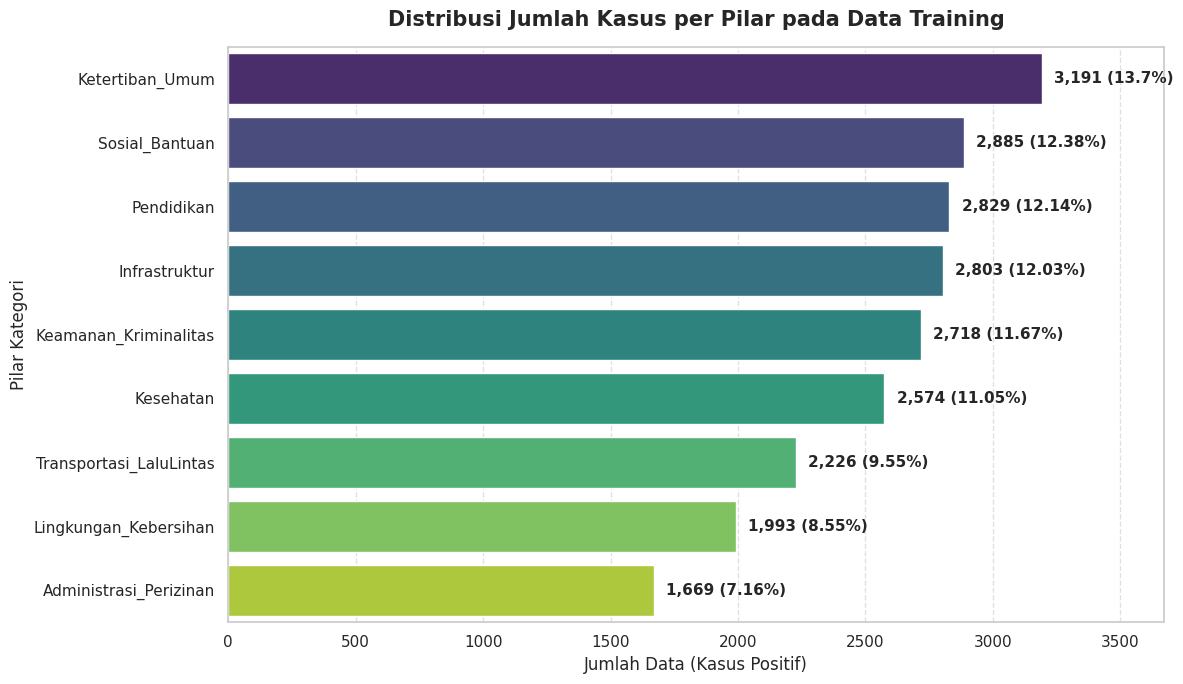


Distribusi Kasus Positif per Pilar:
                  Pilar  Jumlah_Kasus  Persentase
        Ketertiban_Umum          3191       13.70
         Sosial_Bantuan          2885       12.38
             Pendidikan          2829       12.14
          Infrastruktur          2803       12.03
  Keamanan_Kriminalitas          2718       11.67
              Kesehatan          2574       11.05
Transportasi_LaluLintas          2226        9.55
  Lingkungan_Kebersihan          1993        8.55
 Administrasi_Perizinan          1669        7.16

Total sampel training: 23,297

Analisis Class Imbalance:
  Label terbanyak  : Ketertiban_Umum (3,191)
  Label tersedikit : Administrasi_Perizinan (1,669)
  Imbalance Ratio  : 1.9x
  INFO: Distribusi relatif seimbang.


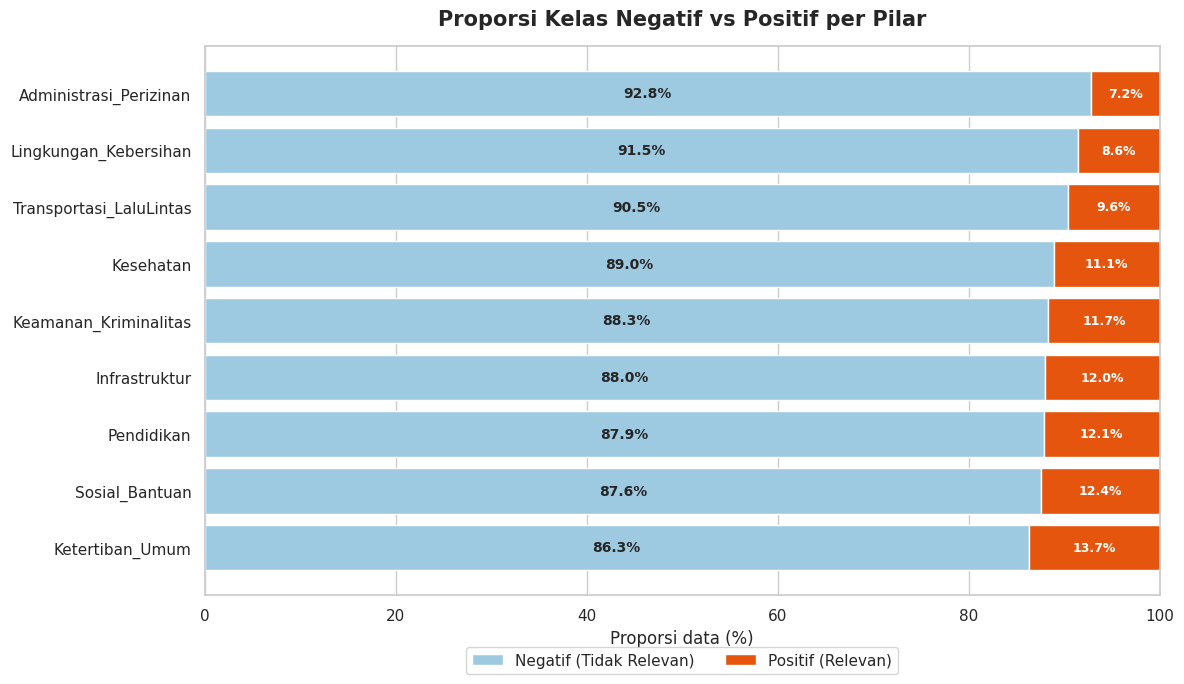


ANALISIS KETIMPANGAN TIAP PILAR (RASIO NEGATIF : POSITIF)
- Administrasi_Perizinan    Neg=21,628 | Pos=1,669 | Rasio = 12.96 : 1 | Positif  7.16% -> Moderat
- Lingkungan_Kebersihan     Neg=21,304 | Pos=1,993 | Rasio = 10.69 : 1 | Positif  8.55% -> Moderat
- Transportasi_LaluLintas   Neg=21,071 | Pos=2,226 | Rasio =  9.47 : 1 | Positif  9.55% -> Moderat
- Kesehatan                 Neg=20,723 | Pos=2,574 | Rasio =  8.05 : 1 | Positif 11.05% -> Moderat
- Keamanan_Kriminalitas     Neg=20,579 | Pos=2,718 | Rasio =  7.57 : 1 | Positif 11.67% -> Moderat
- Infrastruktur             Neg=20,494 | Pos=2,803 | Rasio =  7.31 : 1 | Positif 12.03% -> Moderat
- Pendidikan                Neg=20,468 | Pos=2,829 | Rasio =  7.24 : 1 | Positif 12.14% -> Moderat
- Sosial_Bantuan            Neg=20,412 | Pos=2,885 | Rasio =  7.08 : 1 | Positif 12.38% -> Moderat
- Ketertiban_Umum           Neg=20,106 | Pos=3,191 | Rasio =  6.30 : 1 | Positif 13.70% -> Moderat

Ringkasan:
  Pilar paling timpang : Administrasi_

In [4]:
# ============================================================
# HITUNG DISTRIBUSI KASUS POSITIF PER PILAR
# ============================================================
# Nilai yang dianggap "positif/relevan"
positive_values = ['relevan']

pilar_counts = {}
for col in pilar_cols:
    # Normalisasi: strip spasi, lowercase
    normalized = train_df[col].astype(str).str.strip().str.lower()
    # Hitung hanya yang termasuk kategori positif
    count = normalized.isin(positive_values).sum()
    pilar_counts[col] = count

# Buat Series dan urutkan dari yang terbanyak
counts_series = pd.Series(pilar_counts).sort_values(ascending=False)

# ============================================================
# VISUALISASI DISTRIBUSI
# ============================================================
total_samples = len(train_df)
percentage = (counts_series / total_samples * 100).round(2)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=counts_series.values,
    y=counts_series.index,
    hue=counts_series.index,
    palette='viridis',
    legend=False
)

plt.title('Distribusi Jumlah Kasus per Pilar pada Data Training',
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Jumlah Data (Kasus Positif)', fontsize=12)
plt.ylabel('Pilar Kategori', fontsize=12)

# Label angka + persentase di ujung bar
for i, (v, pct) in enumerate(zip(counts_series.values, percentage.values)):
    plt.text(
        v + (counts_series.max() * 0.015),
        i,
        f"{int(v):,} ({pct}%)",
        va='center', fontsize=11, fontweight='bold'
    )

plt.xlim(0, counts_series.max() * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# TABEL RINGKASAN DISTRIBUSI
dist_df = pd.DataFrame({
    'Pilar': counts_series.index,
    'Jumlah_Kasus': counts_series.values,
    'Persentase': percentage.values
})

print("\nDistribusi Kasus Positif per Pilar:")
print(dist_df.to_string(index=False))
print(f"\nTotal sampel training: {total_samples:,}")

max_cases = counts_series.max()
min_cases = counts_series.min()
imbalance_ratio = max_cases / min_cases if min_cases > 0 else float('inf')

print(f"\nAnalisis Class Imbalance:")
print(f"  Label terbanyak  : {counts_series.idxmax()} ({max_cases:,})")
print(f"  Label tersedikit : {counts_series.idxmin()} ({min_cases:,})")
print(f"  Imbalance Ratio  : {imbalance_ratio:.1f}x")

if imbalance_ratio > 5:
    print("  WARNING: Class imbalance signifikan! Perlu perhatian khusus pada label minoritas.")
elif imbalance_ratio > 2:
    print("  INFO: Ada class imbalance moderat.")
else:
    print("  INFO: Distribusi relatif seimbang.")

# ============================================================
# ANALISIS IMBALANCE DALAM TIAP PILAR (POSITIF vs NEGATIF)
# ============================================================
# Kategori berdasarkan proporsi kelas minoritas (positif), mengikuti rule of thumb
# yang umum dipakai (mis. panduan Google ML Crash Course):
#   >= 40%  -> Seimbang
#   20-40%  -> Ringan  (mild)
#   1-20%   -> Moderat (moderate)
#   < 1%    -> Ekstrem (extreme)
# Catatan: ini heuristik umum, bukan standar baku. Ganti sesuai literatur yang kamu pakai.
def kategori_imbalance(pct_pos):
    if pct_pos >= 40:
        return 'Seimbang'
    elif pct_pos >= 20:
        return 'Ringan'
    elif pct_pos >= 1:
        return 'Moderat'
    return 'Ekstrem'

rows = []
for col in pilar_cols:
    norm = train_df[col].astype(str).str.strip().str.lower()
    pos = int(norm.isin(positive_values).sum())
    neg = total_samples - pos
    pct_pos = pos / total_samples * 100
    rows.append({
        'Pilar': col,
        'Positif': pos,
        'Negatif': neg,
        '%Positif': round(pct_pos, 2),
        '%Negatif': round(100 - pct_pos, 2),
        'Rasio_Neg:Pos': round(neg / pos, 2) if pos > 0 else float('inf'),
        'Kategori': kategori_imbalance(pct_pos),
    })

imb_df = pd.DataFrame(rows).sort_values('Rasio_Neg:Pos', ascending=False).reset_index(drop=True)

# ---------- Diagram: proporsi negatif vs positif per pilar ----------
fig, ax = plt.subplots(figsize=(12, 7))
y_pos = np.arange(len(imb_df))

ax.barh(y_pos, imb_df['%Negatif'], color='#9ecae1', label='Negatif (Tidak Relevan)')
ax.barh(y_pos, imb_df['%Positif'], left=imb_df['%Negatif'], color='#e6550d', label='Positif (Relevan)')
ax.set_yticks(y_pos)
ax.set_yticklabels(imb_df['Pilar'])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Proporsi data (%)', fontsize=12)
ax.set_title('Proporsi Kelas Negatif vs Positif per Pilar', fontsize=15, fontweight='bold', pad=15)

for i, r in imb_df.iterrows():
    ax.text(r['%Negatif'] / 2, i, f"{r['%Negatif']:.1f}%", ha='center', va='center',
            fontsize=10, fontweight='bold')
    ax.text(r['%Negatif'] + r['%Positif'] / 2, i, f"{r['%Positif']:.1f}%", ha='center', va='center',
            fontsize=9, fontweight='bold', color='white')

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.tight_layout()
plt.show()

# ---------- Analisis teks: rasio negatif dan positif ----------
print("\n" + "=" * 70)
print("ANALISIS KETIMPANGAN TIAP PILAR (RASIO NEGATIF : POSITIF)")
print("=" * 70)
for _, r in imb_df.iterrows():
    print(f"- {r['Pilar']:<25} Neg={r['Negatif']:>6,} | Pos={r['Positif']:>5,} | "
          f"Rasio = {r['Rasio_Neg:Pos']:>5.2f} : 1 | Positif {r['%Positif']:>5.2f}% -> {r['Kategori']}")

print("\nRingkasan:")
print(f"  Pilar paling timpang : {imb_df.iloc[0]['Pilar']} ({imb_df.iloc[0]['Rasio_Neg:Pos']:.1f} : 1)")
print(f"  Pilar paling seimbang: {imb_df.iloc[-1]['Pilar']} ({imb_df.iloc[-1]['Rasio_Neg:Pos']:.1f} : 1)")
print(f"  Rata-rata rasio Neg:Pos seluruh pilar: {imb_df['Rasio_Neg:Pos'].mean():.1f} : 1")
print(f"  Sebaran kategori: {imb_df['Kategori'].value_counts().to_dict()}")

# Kesimpulan otomatis: dalam pilar dan antar pilar
print("\nKesimpulan:")
print(f"  [Dalam tiap pilar] Positif hanya {imb_df['%Positif'].min():.1f}%-{imb_df['%Positif'].max():.1f}% "
      f"dari data (rasio {imb_df['Rasio_Neg:Pos'].min():.1f}-{imb_df['Rasio_Neg:Pos'].max():.1f} : 1).")
print("   -> Model rawan menebak '0' terus; F1 kelas 1 akan jadi penentu skor.")
print("   -> Solusi: class weight / pos_weight per pilar, focal loss, dan threshold tuning per label.")
print(f"  [Antar pilar] Selisih frekuensi positif terbesar vs terkecil = {imbalance_ratio:.1f}x.")
print("   -> Pilar kecil bisa tertinggal pada loss gabungan; gunakan stratified split per label")
print("      agar tiap fold memuat cukup positif dari pilar terkecil.")

## 2.3 Handle Missing Values

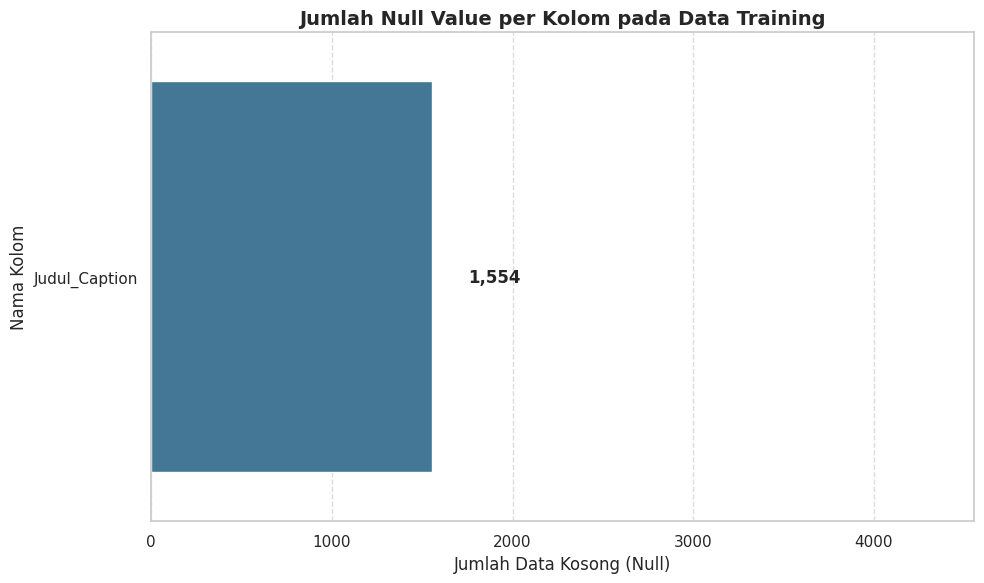

In [5]:
null_counts = train_df.isnull().sum()
null_counts = null_counts[null_counts > 0]

plt.figure(figsize=(10, 6))
sns.barplot(
    x=null_counts.values, 
    y=null_counts.index, 
    hue=null_counts.index,      
    palette='mako', 
    legend=False                
)

plt.title('Jumlah Null Value per Kolom pada Data Training', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Data Kosong (Null)', fontsize=12)
plt.ylabel('Nama Kolom', fontsize=12)

for i, v in enumerate(null_counts.values):
    plt.text(v + 200, i, f"{v:,}", va='center', fontsize=12, fontweight='bold')

plt.xlim(0, null_counts.max() + 3000)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [6]:
print("PREPROCESSING: HANDLE MISSING VALUES")

# Isi NaN dengan string kosong (bukan "nan") untuk mencegah artefak
for df in [train_df, test_df]:
    df['Judul_Caption'] = df['Judul_Caption'].fillna('')
    df['Teks'] = df['Teks'].fillna('')

print("Missing values diisi dengan string kosong\n")

train_df.info()

PREPROCESSING: HANDLE MISSING VALUES
Missing values diisi dengan string kosong

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23297 entries, 0 to 23296
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ID                       23297 non-null  int64 
 1   Teks                     23297 non-null  object
 2   Judul_Caption            23297 non-null  object
 3   Source                   23297 non-null  object
 4   Tanggal_Upload           23297 non-null  object
 5   Infrastruktur            23297 non-null  object
 6   Kesehatan                23297 non-null  object
 7   Administrasi_Perizinan   23297 non-null  object
 8   Lingkungan_Kebersihan    23297 non-null  object
 9   Ketertiban_Umum          23297 non-null  object
 10  Transportasi_LaluLintas  23297 non-null  object
 11  Sosial_Bantuan           23297 non-null  object
 12  Keamanan_Kriminalitas    23297 non-null  object
 13  Pendidikan 

## 2.4 Noise pada Data

Menghitung 21 jenis noise pada 23,297 baris ...
Kandidat typo unik yang ditemukan: 1,446 kata

RINGKASAN PREVALENSI NOISE (persentase dari total baris)
                                  Noise  Jumlah_Baris  Persentase
                                  Emoji         14595       62.65
   Slang / kolokial (gak, banget, wkwk)          8107       34.80
      Singkatan informal (yg, dgn, tdk)          7183       30.83
               Elongasi huruf (paraaah)          3602       15.46
                     Leetspeak (p4rk1r)          3600       15.45
   Zero-width / karakter tak kasat mata          3036       13.03
   Pengulangan tanda baca (!!! ??? ...)          2806       12.04
          Fullwidth (huruf lebar penuh)          2068        8.88
 Homoglyph Cyrillic (huruf mirip Latin)          1894        8.13
Huruf dipisah titik/spasi (p.a.r.k.i.r)          1785        7.66
 Substitusi fonetik (aq, anak2, makasi)          1779        7.64
          Typo / salah ketik (estimasi)          1522   

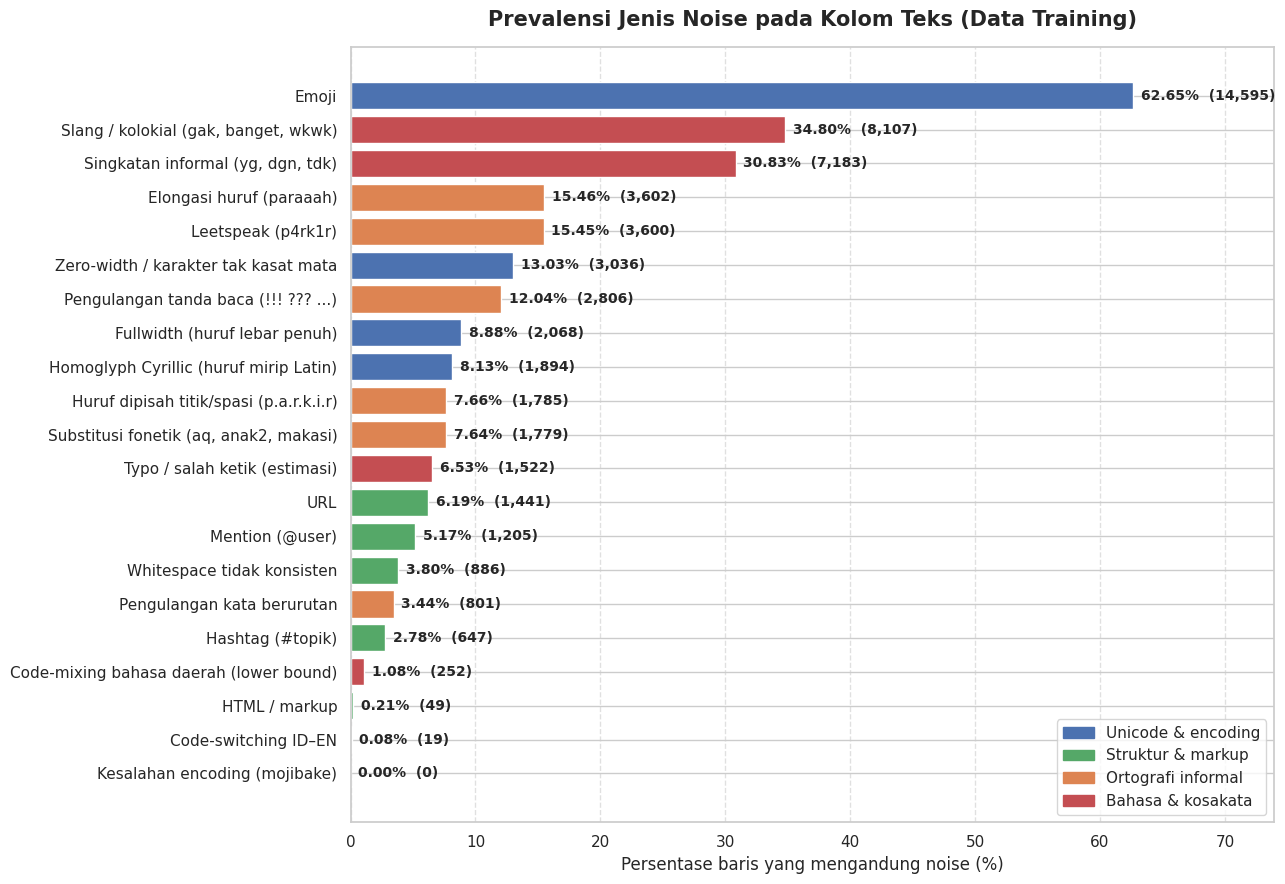


CONTOH BARIS UNTUK SETIAP JENIS NOISE

■ Zero-width / karakter tak kasat mata  [3,036 baris]
   • baris 5028 | bukti: ​, ‍
     teks: Tapi gimana yg tinggal di jawa barat tp k⟦ZWSP⟧t⟦ZWSP⟧p jakarta kmren minta rujukan buat ke rs yg di tuju gak bisa katanya 🥺 🤦⟦ZWJ⟧♂️
   • baris 1083 | bukti: ‍
     teks: Bagus lah b14r pda kappk. Klo itu bkan tmpat p.a.r.k.i.r 🤦⟦ZWJ⟧♂️

■ Fullwidth (huruf lebar penuh)  [2,068 baris]
   • baris 10070 | bukti: ｒｅｓａｈ
     teks: Tr0t04r bagus tp pejalan kaki ｒｅｓａｈ,, ribet dan kumuh,,,, , apxzezc yg раrkіr, рkl dan jukir liat sdh ga ada vewe ezwpclydt bg pejalan kaki..
   • baris 8775 | bukti: ｂｐｎｔ
     teks: Lelah qjqfm mfyn ini menunggu ｂｐｎｔ cair kapan kapan jhpyufh dong😮 🙄

■ Homoglyph Cyrillic (huruf mirip Latin)  [1,894 baris]
   • baris 8643 | bukti: р
     teks: Padahal bрjs jg bayar ga rcletd tp knp 0hybz semua ｄｉｐｅｒｓｕｌｉｔ astaga 😭
   • baris 5435 | bukti: е, а
     teks: Jakarta Selatan ada bеgаl dikejar sampai lobang semut 🛵

■ Kesalahan encoding 

In [7]:
raw = train_df['Teks'].fillna('').astype(str)
N = len(raw)

ZW_CHARS = '\u200b\u200c\u200d\ufeff\u2060\u00ad\u200e\u200f'
RE_ZW    = re.compile(f'[{ZW_CHARS}]')
RE_URL   = re.compile(r'https?://\S+|www\.\S+', re.I)
RE_MENT  = re.compile(r'@\w+')
RE_HASH  = re.compile(r'#\w+')

def base_text(s):
    """Versi 'netral' untuk detektor berbasis kata: NFKC, buang zero-width,
    lowercase, buang URL/mention/hashtag (agar token URL tidak dihitung sebagai noise lain)."""
    s = unicodedata.normalize('NFKC', s)
    s = RE_ZW.sub('', s).lower()
    s = RE_URL.sub(' ', s)
    s = RE_MENT.sub(' ', s)
    s = RE_HASH.sub(' ', s)
    return s

def tokenization(s):
    return re.findall(r"[a-z0-9]+", base_text(s))

base_tokens = [tokenization(s) for s in raw]          # cache token per baris

def vis(s, maxlen=170):
    """Tampilkan karakter tak kasat mata agar terlihat di contoh."""
    rep = {'\u200b':'⟦ZWSP⟧','\u200c':'⟦ZWNJ⟧','\u200d':'⟦ZWJ⟧','\ufeff':'⟦BOM⟧','\u2060':'⟦WJ⟧',
           '\u00ad':'⟦SHY⟧','\u200e':'⟦LRM⟧','\u200f':'⟦RLM⟧','\u00a0':'⟦NBSP⟧','\t':'⟦TAB⟧',
           '\n':'⟦NL⟧','\r':'⟦CR⟧'}
    for k, v in rep.items(): s = s.replace(k, v)
    return s if len(s) <= maxlen else s[:maxlen] + '…'

# ------------------------------------------------------------
# 1. LEKSIKON (daftar kata) — dibuat terpisah (tidak saling tumpang tindih)
# ------------------------------------------------------------
ABBR = set("""yg dgn dg utk untk tdk tdak krn krna jgn jd jdi sdh sdg blm blom sbg sbgai spt dlm dpt
tp tpi bgt bngt bs pd hrs kpd org orng tmn skrg skrng dll dsb dst dkk sm smua smpe bkn bnyk bnr brp
brpa byk emg hny jg kmrn krg lbh mrk msh sdkt sll stlh sblm tgl thn trs trims trmksh wkt gmn gmna
knp kpn dmn dmna""".split())

SLANG = set("""gue gw gua gwe lu lo loe elu gak ga nggak ngga nggk enggak engga ogah doang aja aj udah udh dah
sih deh dong nih tuh lah mah kok banget emang kayak kayaknya gimana kenapa ntar entar sampe cuma pake
bikin males ribet lemot kesel ngomong nyari pengen mending bener anjir anjay anjrit bjir woi woy cuy bro
sis gan sob ngab santuy mager baper bucin kepo receh cuan gabut gaje woles kuy mantul gercep kudu""".split())
SLANG -= ABBR
RE_LAUGH = re.compile(r'\b(?:wk){2,}\w*|\bw?k{3,}\b|\b(?:ha){2,}h?\b|\b(?:he){2,}h?\b|\b(?:hi){2,}\b|\bkwkw+\b')

PHON = set("aq kq aqu akuh plis pliss plisss gaes gais makasi makasih thx thanx tengkyu ciyus miapa".split())
Q_SAFE = {'qatar','iraq','tariq','qiblat','qadir','qolbu','quran','alquran'}

ENG = set("""the and you are was were this that with for not but just very can will have has had what why how when
where because please love good bad thank thanks sorry hello from they them their our your his her she its been
being more much some any would could should really also only still already never always people government
city road traffic hospital school free fix need want help work make take like""".split())
IND_FUNC = set("""yang dan di ke dari ini itu tidak gak ga nggak aja untuk dengan saya aku kita kami sudah udah
belum ada bisa juga atau karena kalau kalo sama mau lagi jadi pada oleh akan harus sih deh dong banget""".split())

REGIONAL = set("""ora wae wong iki kuwi kui kowe koe opo piye mung jare sampeyan gawe nuwun suwun tenan
teu euy atuh kumaha naon abdi hayang pisan kitu ieu eta geus keur kedah hoyong mangga nuhun punten
kagak ngape kemane ane ente gile indak nyo ndak""".split())

# ------------------------------------------------------------
# 2. DETEKTOR TYPO (berbasis korpus: kata langka yang berjarak 1 edit dari kata sangat sering)
# ------------------------------------------------------------
alpha_tokens = [[t for t in toks if t.isalpha()] for toks in base_tokens]
freq = Counter(t for toks in alpha_tokens for t in toks)
EXCL = ABBR | SLANG | PHON | ENG | IND_FUNC
FREQUENT = {w for w, c in freq.items() if c >= 50 and len(w) >= 4}
ALPHABET = 'abcdefghijklmnopqrstuvwxyz'

def edits1(w):
    sp = [(w[:i], w[i:]) for i in range(len(w) + 1)]
    dele = [a + b[1:] for a, b in sp if b]
    trans = [a + b[1] + b[0] + b[2:] for a, b in sp if len(b) > 1]
    repl = [a + c + b[1:] for a, b in sp if b for c in ALPHABET]
    ins = [a + c + b for a, b in sp for c in ALPHABET]
    return set(dele + trans + repl + ins)

typo_map = {}
for w, c in freq.items():
    if c > 2 or len(w) < 5 or len(w) > 14 or w in FREQUENT or w in EXCL:
        continue
    if re.search(r'(.)\1\1', w):          # elongasi bukan typo
        continue
    hits = [e for e in edits1(w) if e in FREQUENT and e[0] == w[0] and freq[e] >= 25 * c]
    if hits:
        typo_map[w] = max(hits, key=lambda e: freq[e])

# ------------------------------------------------------------
# 3. DETEKTOR PER JENIS NOISE  -> mengembalikan list bukti (kosong = tidak ada)
# ------------------------------------------------------------
def rx(pattern, flags=0, on='raw'):
    r = re.compile(pattern, flags)
    def f(i):
        s = raw.iat[i] if on == 'raw' else base_text(raw.iat[i])
        return [m.group(0) for m in r.finditer(s)]
    return f

def d_leet(i):
    """Token campuran huruf+angka, KECUALI angka hanya di awal (11malem, 5km) atau hanya di akhir (mp3, covid19)."""
    out = []
    for t in base_tokens[i]:
        if not (re.search(r'[a-z]', t) and re.search(r'\d', t)): continue
        if re.fullmatch(r'\d+[a-z]+', t) or re.fullmatch(r'[a-z]+\d+', t): continue
        out.append(t)
    return out

def d_abbr(i):  return [t for t in base_tokens[i] if t in ABBR]
def d_slang(i):
    out = [t for t in base_tokens[i] if t in SLANG]
    out += RE_LAUGH.findall(base_text(raw.iat[i]))
    return out
def d_phon(i):
    out = []
    for t in base_tokens[i]:
        if (t in PHON or re.fullmatch(r'[a-z]{3,}2', t) or re.fullmatch(r'(?:aku|kamu|iya|itu|ini|mau)h+', t)
                or (len(t) <= 3 and 'q' in t and t.isalpha() and t not in Q_SAFE)):
            out.append(t)
    return out
def d_typo(i):  return [f'{t}→{typo_map[t]}' for t in alpha_tokens[i] if t in typo_map]
def d_wordrep(i):
    return [m.group(0) for m in re.finditer(r'\b([a-z]{2,})(?:\s+\1\b)+', base_text(raw.iat[i]))]
def d_code(i):
    toks = base_tokens[i]
    eng = sorted({t for t in toks if t in ENG}); ind = {t for t in toks if t in IND_FUNC}
    return eng if (len(eng) >= 2 and len(ind) >= 2) else []
def d_regional(i):
    hits = sorted({t for t in base_tokens[i] if t in REGIONAL})
    return hits if len(hits) >= 2 else []
def d_spaced(i):
    t = unicodedata.normalize('NFKC', RE_ZW.sub('', raw.iat[i]))
    return [m.group(0) for m in re.finditer(r'\b(?:[A-Za-z][. ]){3,}[A-Za-z]\b', t)]
def d_space(i):
    s = raw.iat[i]; out = []
    if re.search(r'[ ]{2,}', s):                                  out.append('spasi ganda')
    if '\t' in s:                                                 out.append('tab')
    if re.search(r'[\r\n]', s):                                   out.append('baris baru')
    if re.search(r'[\u00a0\u2000-\u200a\u202f\u205f\u3000]', s):  out.append('spasi unicode non-standar')
    if s != s.strip():                                            out.append('spasi di tepi')
    return out

RE_EMOJI = r'[\U0001F000-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF\u203c\u2049\ufe0f]'
RE_MOJIBAKE = (r'\ufffd|[\x80-\x9f]|Ã[\u0080-\u00bf]|Â[\u00a0-\u00bf]|â€[™œ\u009d\u201c\u201d\u2122\u00a6]?|ðŸ[\u0080-\u00bf\u0152\u0153\u0161\u017e\u2018-\u203a]*')
RE_HTML = r'<\/?[a-zA-Z][^>]{0,80}>|&(?:amp|lt|gt|quot|apos|nbsp|#\d{2,5}|#x[0-9a-fA-F]{2,4});|\*\*[^*]+\*\*|\[[^\]]+\]\([^)]+\)'

NOISES = [
 # (nama, kelompok, detektor)
('Zero-width / karakter tak kasat mata',     'Unicode & encoding', rx(f'[{ZW_CHARS}]')),
('Fullwidth (huruf lebar penuh)',            'Unicode & encoding', rx(r'[\uff01-\uff5e]+')),
('Homoglyph Cyrillic (huruf mirip Latin)',   'Unicode & encoding', rx(r'[\u0400-\u04ff]+')),
('Kesalahan encoding (mojibake)',            'Unicode & encoding', rx(RE_MOJIBAKE)),
('Emoji',                                    'Unicode & encoding', rx(RE_EMOJI)),
('HTML / markup',                            'Struktur & markup',  rx(RE_HTML)),
('Whitespace tidak konsisten',               'Struktur & markup',  d_space),
('URL',                                      'Struktur & markup',  rx(r'https?://\S+|www\.\S+', re.I)),
('Mention (@user)',                          'Struktur & markup',  rx(r'@\w+')),
('Hashtag (#topik)',                         'Struktur & markup',  rx(r'#\w+')),
('Pengulangan tanda baca (!!! ??? ...)',     'Ortografi informal', rx(r'[!?]{2,}|([.,~])\1{2,}')),
('Elongasi huruf (paraaah)',                 'Ortografi informal', rx(r'([a-z])\1{2,}', 0, on='base')),
('Huruf dipisah titik/spasi (p.a.r.k.i.r)',  'Ortografi informal', d_spaced),
('Leetspeak (p4rk1r)',                       'Ortografi informal', d_leet),
('Substitusi fonetik (aq, anak2, makasi)',   'Ortografi informal', d_phon),
('Pengulangan kata berurutan',               'Ortografi informal', d_wordrep),
('Singkatan informal (yg, dgn, tdk)',        'Bahasa & kosakata',  d_abbr),
('Slang / kolokial (gak, banget, wkwk)',     'Bahasa & kosakata',  d_slang),
('Typo / salah ketik (estimasi)',            'Bahasa & kosakata',  d_typo),
('Code-switching ID–EN',                     'Bahasa & kosakata',  d_code),
('Code-mixing bahasa daerah (lower bound)',  'Bahasa & kosakata',  d_regional),
]

# ------------------------------------------------------------
# 4. HITUNG: jalankan tiap detektor di setiap baris
# ------------------------------------------------------------
print(f"Menghitung {len(NOISES)} jenis noise pada {N:,} baris ...")
rows, evid = [], {}
for name, grp, fn in NOISES:
    ev = [fn(i) for i in range(N)]
    evid[name] = ev
    n_hit = sum(1 for e in ev if len(e) > 0)
    rows.append({'Noise': name, 'Kelompok': grp, 'Jumlah_Baris': n_hit,
                 'Persentase': round(n_hit / N * 100, 2)})

noise_df = pd.DataFrame(rows).sort_values('Persentase', ascending=False).reset_index(drop=True)
print(f"Kandidat typo unik yang ditemukan: {len(typo_map):,} kata")
print("\nRINGKASAN PREVALENSI NOISE (persentase dari total baris)")
print(noise_df[['Noise', 'Jumlah_Baris', 'Persentase']].to_string(index=False))

# ------------------------------------------------------------
# 5. DIAGRAM BATANG
# ------------------------------------------------------------
warna = {'Unicode & encoding': '#4c72b0', 'Struktur & markup': '#55a868',
         'Ortografi informal': '#dd8452', 'Bahasa & kosakata': '#c44e52'}
plot_df = noise_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(13, 9))
ax.barh(plot_df['Noise'], plot_df['Persentase'], color=[warna[g] for g in plot_df['Kelompok']])
xmax = max(plot_df['Persentase'].max(), 1)
for y, (p, n) in enumerate(zip(plot_df['Persentase'], plot_df['Jumlah_Baris'])):
    ax.text(p + xmax * 0.01, y, f'{p:.2f}%  ({n:,})', va='center', fontsize=10, fontweight='bold')
ax.set_xlim(0, xmax * 1.18)
ax.set_xlabel('Persentase baris yang mengandung noise (%)', fontsize=12)
ax.set_title('Prevalensi Jenis Noise pada Kolom Teks (Data Training)', fontsize=15, fontweight='bold', pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.6)
ax.legend(handles=[Patch(color=c, label=g) for g, c in warna.items()], loc='lower right')
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 6. CONTOH DATA (2 baris per noise)
# ------------------------------------------------------------
rng = random.Random(42)
print("\n" + "=" * 90 + "\nCONTOH BARIS UNTUK SETIAP JENIS NOISE\n" + "=" * 90)
for name, grp, fn in NOISES:
    ev = evid[name]
    hit_idx = [i for i, e in enumerate(ev) if e]
    short = [i for i in hit_idx if len(raw.iat[i]) <= 200]
    pool = short if len(short) >= 2 else hit_idx
    print(f"\n■ {name}  [{len(hit_idx):,} baris]")
    if not hit_idx:
        print("   (tidak ada baris terdeteksi — noise ini tidak ditemukan pada data)")
        continue
    for i in rng.sample(pool, min(2, len(pool))):
        bukti = ', '.join(dict.fromkeys(ev[i]))[:80]
        print(f"   • baris {train_df.index[i]} | bukti: {bukti}")
        print(f"     teks: {vis(raw.iat[i])}")

## 2.5 Membersihkan Kata

In [8]:
import re, html, unicodedata
 
# --- 1. Karakter tak kasat mata (ditambah Hangul filler yang ditemukan di data) ---
INVISIBLE = ('\u200b\u200c\u200d\u200e\u200f\u2060\u2061\u2062\u2063\u00ad\ufeff'
             '\u115f\u1160\u3164\uffa0\u2800\ufe0e\ufe0f')
RE_INVIS = re.compile(f'[{INVISIBLE}]')
 
# --- 2. Homoglyph -> Latin (pemetaan karakter Unicode, BUKAN kamus kata) ---
# Dipetakan setelah lowercase. Hanya huruf yang benar-benar muncul/mirip Latin.
HOMOGLYPH = str.maketrans({
    'а':'a','в':'b','с':'c','е':'e','ё':'e','н':'h','һ':'h','і':'i','ї':'i','ј':'j',
    'к':'k','ӏ':'l','м':'m','о':'o','р':'p','ԛ':'q','ѕ':'s','т':'t','у':'y','х':'x',
    'ѵ':'v','ԁ':'d','ԝ':'w',
    'ο':'o','α':'a','ν':'v','ρ':'p','ι':'i','κ':'k','τ':'t',
})
 
RE_URL   = re.compile(r'https?://\S+|www\.\S+', re.I)
RE_MENT  = re.compile(r'@\w+')
RE_HASH  = re.compile(r'#(\w+)')
# huruf dipisah titik/spasi: "p.a.r.k.i.r", "m a h a s i s w a" (>=4 huruf tunggal)
RE_SPACED = re.compile(r'(?<![a-z0-9])(?:[a-z] ){3,}[a-z](?![a-z0-9])'      # spasi: >=4 huruf
                       r'|(?<![a-z0-9])(?:[a-z]\.){2,}[a-z](?![a-z0-9])')    # titik: >=3 huruf (k.t.p)
RE_TOKEN  = re.compile(r'[a-z0-9]+')
LEET = str.maketrans({'0':'o','1':'i','3':'e','4':'a','5':'s','7':'t'})
RE_ELONG = re.compile(r'([a-z])\1{2,}')
RE_PUNCT_REP = re.compile(r'([!?])\1+|[.,~]{2,}')
RE_EMOJI = re.compile(r'([\U0001F000-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF])')
 
def _despace(m):
    return re.sub(r'[ .]', '', m.group(0))
 
def _unleet(m):
    t = m.group(0)
    has_l, has_d = re.search(r'[a-z]', t), re.search(r'\d', t)
    if not (has_l and has_d): return t
    # angka hanya di awal (5km, 11malem) atau hanya di akhir (covid19, anak2): biarkan
    if re.fullmatch(r'\d+[a-z]+', t) or re.fullmatch(r'[a-z]+\d+', t): return t
    return t.translate(LEET)
 
def _elong(m):
    ch = m.group(1)
    return ch * (2 if ch in 'aiueo' else 1)   # vokal -> 2, konsonan -> 1
 
def structural_clean(text, *, homoglyph=True, despace=True, leet=True,
                     elong=True, punct=True, url_mention=True, emoji_sep=True):
    """Pembersihan struktural tanpa kamus kata. Tiap langkah bisa dimatikan (untuk ablation)."""
    if not isinstance(text, str):
        return ""
    text = html.unescape(text)                       # &amp; -> &
    text = unicodedata.normalize('NFKC', text)       # fullwidth -> ASCII
    text = RE_INVIS.sub('', text)                    # zero-width + hangul filler
    text = text.lower()
    if homoglyph:
        text = text.translate(HOMOGLYPH)             # Cyrillic/Greek -> Latin
    if url_mention:
        text = RE_URL.sub(' ', text)
        text = RE_MENT.sub(' ', text)
        text = RE_HASH.sub(r' \1 ', text)            # #infobdg -> infobdg
    if despace:
        text = RE_SPACED.sub(_despace, text)
    if leet:
        text = RE_TOKEN.sub(_unleet, text)
    if elong:
        text = RE_ELONG.sub(_elong, text)
    if punct:
        text = RE_PUNCT_REP.sub(lambda m: ' ' + (m.group(1) or '') + ' ', text)
    if emoji_sep:
        text = RE_EMOJI.sub(r' \1 ', text)           # emoji jadi token tersendiri
    return re.sub(r'\s+', ' ', text).strip()
 
 
# Penggabungan judul + teks (DIPAKAI BERSAMA oleh ablation dan final_text agar konsisten)
SEP = ' [SEP] '
def build_final_text(judul, teks):
    """judul & teks sudah dibersihkan. Judul kosong -> hanya teks (tanpa SEP)."""
    return teks if judul == '' else f'{judul}{SEP}{teks}'
 
 
# ------------------------------------------------------------
# ABLATION: ukur kontribusi tiap langkah dengan CV
# Metrik: F1 kelas POSITIF ("Relevan") per label, dirata-ratakan 9 label.
#   - F1@0.5     : threshold tetap 0.5
#   - F1@tuned   : threshold terbaik per label (grid 0.10-0.88), lebih adil karena
#                  class_weight='balanced' menggeser probabilitas.
# (Versi lama memakai average='macro' DI DALAM satu label = rata-rata F1 kelas 0 dan kelas 1,
#  sehingga angkanya ~0.92 dan perbedaan antar konfigurasi tertelan oleh kelas 0.)
# ------------------------------------------------------------
_GRID = np.round(np.arange(0.10, 0.90, 0.02), 2)
 
def _best_f1(y, p):
    pred = p[:, None] >= _GRID[None, :]
    pos = (y == 1)[:, None]
    tp = (pred & pos).sum(0); fp = pred.sum(0) - tp; fn = pos.sum() - tp
    return float((2 * tp / np.maximum(2 * tp + fp + fn, 1)).max())
 
def run_ablation(train_df, target_cols, y_train, n_splits=5, seed=42, sample=None):
    from scipy.sparse import hstack
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import f1_score
    from sklearn.model_selection import KFold
 
    steps = ['homoglyph', 'despace', 'leet', 'elong', 'punct', 'url_mention', 'emoji_sep']
    configs = {'baseline (NFKC+ZW saja)': {s: False for s in steps},
               'FULL v2': {s: True for s in steps}}
    for s in steps:                                   # leave-one-out
        configs[f'FULL tanpa {s}'] = {k: (k != s) for k in steps}
 
    idx = np.arange(len(train_df))
    if sample: idx = np.random.RandomState(seed).choice(idx, sample, replace=False)
    Y = np.asarray(y_train)[idx]
    folds = list(KFold(n_splits, shuffle=True, random_state=seed).split(idx))
    rows = []
    for name, cfg in configs.items():
        jud = train_df['Judul_Caption'].fillna('').iloc[idx].map(lambda t: structural_clean(t, **cfg))
        tek = train_df['Teks'].fillna('').iloc[idx].map(lambda t: structural_clean(t, **cfg))
        txt = np.array([build_final_text(j, t) for j, t in zip(jud, tek)], dtype=object)
        oof = np.zeros(Y.shape)
        for tr, va in folds:
            w = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
            c = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, sublinear_tf=True)
            Xtr = hstack([w.fit_transform(txt[tr]), c.fit_transform(txt[tr])]).tocsr()
            Xva = hstack([w.transform(txt[va]), c.transform(txt[va])]).tocsr()
            for j in range(Y.shape[1]):
                m = LogisticRegression(C=4, max_iter=300, class_weight='balanced').fit(Xtr, Y[tr, j])
                oof[va, j] = m.predict_proba(Xva)[:, 1]
        f05 = [f1_score(Y[:, j], oof[:, j] >= 0.5, zero_division=0) for j in range(Y.shape[1])]
        ftu = [_best_f1(Y[:, j], oof[:, j]) for j in range(Y.shape[1])]
        rows.append({'Konfigurasi': name, 'F1@0.5': np.mean(f05), 'F1@tuned': np.mean(ftu),
                     **dict(zip(target_cols, ftu))})
        print(f"{name:32s} F1@0.5={np.mean(f05):.4f}  F1@tuned={np.mean(ftu):.4f}")
    return pd.DataFrame(rows).sort_values('F1@tuned', ascending=False)
 
# ============================================================
# TERAPKAN pembersihan v2 ke data train & test  -> membuat kolom final_text
# (tanpa langkah ini, sel modeling akan error "Kolom 'final_text' belum ada",
#  dan sel 2.7 tidak akan pernah menunjukkan angka noise yang berbeda)
# ============================================================
print("Menerapkan structural_clean v2 ...")
for _d in (train_df, test_df):
    _d['clean_judul'] = _d['Judul_Caption'].fillna('').map(structural_clean)
    _d['clean_teks']  = _d['Teks'].fillna('').map(structural_clean)
    _d['final_text']  = [build_final_text(j, t) for j, t in zip(_d['clean_judul'], _d['clean_teks'])]
 
_raw_tr = train_df['Teks'].fillna('').astype(str)
print(f"  train: {len(train_df):,} baris | test: {len(test_df):,} baris -> kolom 'clean_teks', 'clean_judul', 'final_text' dibuat")
print(f"  Baris Teks train yang berubah oleh cleaning : {(_raw_tr != train_df['clean_teks']).mean()*100:.1f}%")
print(f"  final_text kosong -> train: {int((train_df['final_text'].str.strip() == '').sum())}"
      f" | test: {int((test_df['final_text'].str.strip() == '').sum())}")

Menerapkan structural_clean v2 ...
  train: 23,297 baris | test: 34,687 baris -> kolom 'clean_teks', 'clean_judul', 'final_text' dibuat
  Baris Teks train yang berubah oleh cleaning : 91.5%
  final_text kosong -> train: 0 | test: 0


## 2.6 Studi Ablasi Pada Pra Pemrosesan

In [9]:
RUN_ABLATION = False          # ubah ke True untuk menjalankan ulang dengan metrik yang benar
 
y_abl = np.stack(
    [(train_df[c].astype(str).str.strip().str.lower() == 'relevan').astype(int).values
     for c in pilar_cols], axis=1)
 
if RUN_ABLATION:
    abl = run_ablation(train_df, pilar_cols, y_abl, n_splits=5)
    print()
    print(abl[['Konfigurasi', 'F1@0.5', 'F1@tuned']].to_string(index=False))
else:
    print("Ablation dilewati (RUN_ABLATION=False).")
 
# Arsip hasil run pertama -- METRIK LAMA (macro dua-kelas per label), TIDAK sebanding dengan metrik baru:
#   baseline (NFKC+ZW saja)          0.9246
#   FULL v2                          0.9276
#   FULL tanpa homoglyph             0.9258
#   FULL tanpa despace               0.9266
#   FULL tanpa leet                  0.9264
#   FULL tanpa elong                 0.9274
#   FULL tanpa punct                 0.9274
#   FULL tanpa url_mention           0.9271
#   FULL tanpa emoji_sep             0.9270

# baseline (NFKC+ZW saja)          F1@0.5=0.8665  F1@tuned=0.8741
# FULL v2                          F1@0.5=0.8715  F1@tuned=0.8786
# FULL tanpa homoglyph             F1@0.5=0.8703  F1@tuned=0.8777
# FULL tanpa despace               F1@0.5=0.8697  F1@tuned=0.8769
# FULL tanpa leet                  F1@0.5=0.8698  F1@tuned=0.8764
# FULL tanpa elong                 F1@0.5=0.8717  F1@tuned=0.8782
# FULL tanpa punct                 F1@0.5=0.8714  F1@tuned=0.8786
# FULL tanpa url_mention           F1@0.5=0.8717  F1@tuned=0.8787
# FULL tanpa emoji_sep             F1@0.5=0.8716  F1@tuned=0.8785

#             Konfigurasi   F1@0.5  F1@tuned
#  FULL tanpa url_mention 0.871721  0.878658
#                 FULL v2 0.871487  0.878629
#        FULL tanpa punct 0.871421  0.878562
#    FULL tanpa emoji_sep 0.871635  0.878475
#        FULL tanpa elong 0.871730  0.878211
#    FULL tanpa homoglyph 0.870289  0.877722
#      FULL tanpa despace 0.869706  0.876885
#         FULL tanpa leet 0.869845  0.876361
# baseline (NFKC+ZW saja) 0.866519  0.874058

Ablation dilewati (RUN_ABLATION=False).


## 2.7 Hasil Pra Pemrosesan

Mengukur 21 jenis noise pada 23,297 baris (sebelum & sesudah cleaning) ...

PERBANDINGAN PREVALENSI NOISE (jumlah baris dari total train)
                                  Noise  Sebelum  Sesudah  %Sebelum  %Sesudah  Turun
                                  Emoji    14595    13791     62.65     59.20    804
   Slang / kolokial (gak, banget, wkwk)     8107     8173     34.80     35.08    -66
      Singkatan informal (yg, dgn, tdk)     7183     7193     30.83     30.88    -10
               Elongasi huruf (paraaah)     3602        0     15.46      0.00   3602
                     Leetspeak (p4rk1r)     3600      604     15.45      2.59   2996
   Zero-width / karakter tak kasat mata     3036        0     13.03      0.00   3036
   Pengulangan tanda baca (!!! ??? ...)     2806       30     12.04      0.13   2776
          Fullwidth (huruf lebar penuh)     2068        0      8.88      0.00   2068
 Homoglyph Cyrillic (huruf mirip Latin)     1894        1      8.13      0.00   1893
Huruf dipisa

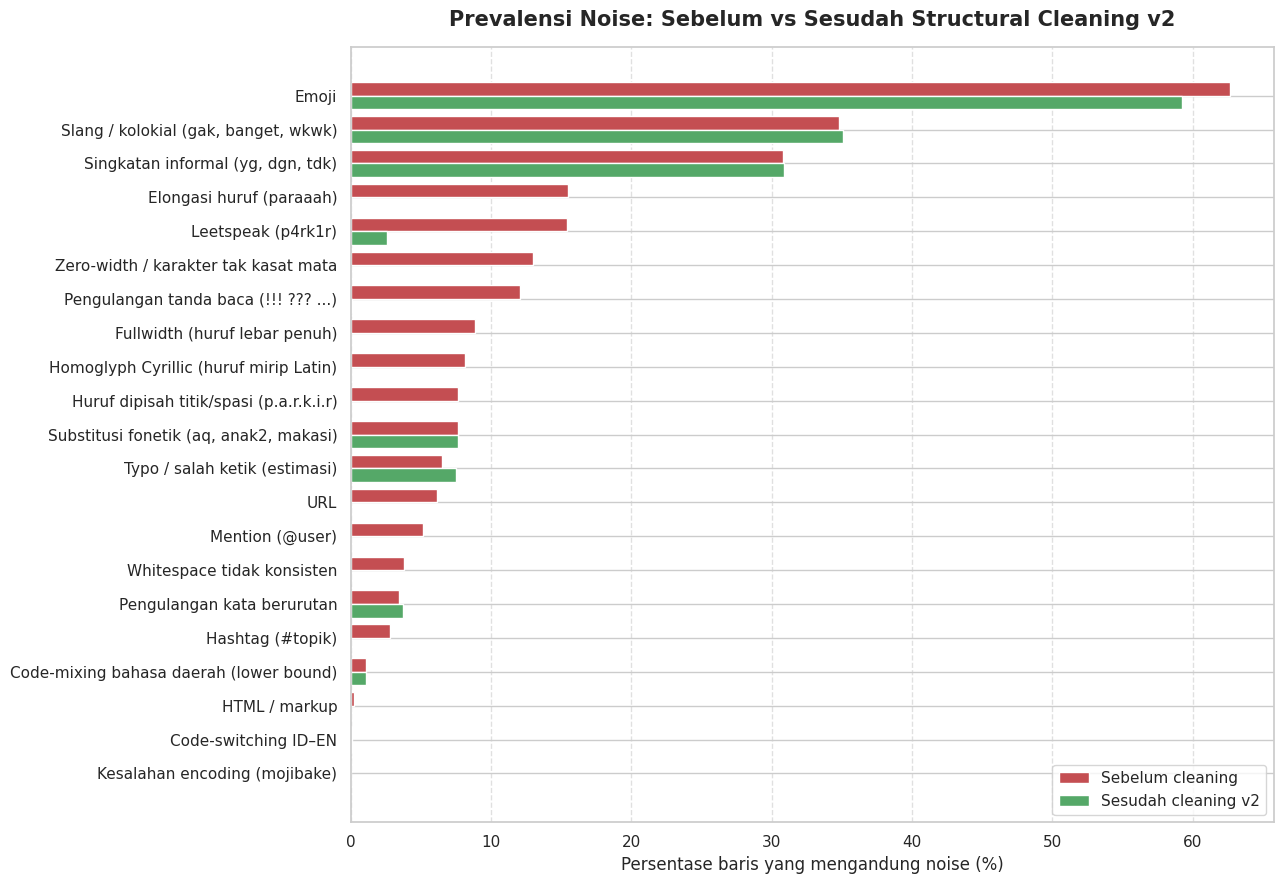

In [10]:
def measure_noise(texts):
    """Jalankan 21 detektor (NOISES, sel 2.4) pada kumpulan teks -> dict {nama noise: jumlah baris}."""
    global raw, base_tokens, alpha_tokens
    saved = (raw, base_tokens, alpha_tokens)
    try:
        raw = pd.Series(list(texts), dtype=object).astype(str)           # indeks 0..n-1 (detektor pakai .iat)
        base_tokens  = [tokenization(s) for s in raw]
        alpha_tokens = [[t for t in toks if t.isalpha()] for toks in base_tokens]
        return {name: sum(1 for i in range(len(raw)) if len(fn(i)) > 0) for name, grp, fn in NOISES}
    finally:
        raw, base_tokens, alpha_tokens = saved                            # kembalikan state sel 2.4
 
n_rows = len(train_df)
print(f"Mengukur {len(NOISES)} jenis noise pada {n_rows:,} baris (sebelum & sesudah cleaning) ...")
cnt_before = measure_noise(train_df['Teks'].fillna('').astype(str))
cnt_after  = measure_noise(train_df['clean_teks'])
 
noise_cmp = pd.DataFrame({
    'Noise':    [n for n, g, f in NOISES],
    'Kelompok': [g for n, g, f in NOISES],
    'Sebelum':  [cnt_before[n] for n, g, f in NOISES],
    'Sesudah':  [cnt_after[n]  for n, g, f in NOISES],
})
noise_cmp['%Sebelum'] = (noise_cmp['Sebelum'] / n_rows * 100).round(2)
noise_cmp['%Sesudah'] = (noise_cmp['Sesudah'] / n_rows * 100).round(2)
noise_cmp['Turun']    = noise_cmp['Sebelum'] - noise_cmp['Sesudah']
noise_cmp = noise_cmp.sort_values('%Sebelum', ascending=False).reset_index(drop=True)
 
print("\nPERBANDINGAN PREVALENSI NOISE (jumlah baris dari total train)")
print(noise_cmp[['Noise', 'Sebelum', 'Sesudah', '%Sebelum', '%Sesudah', 'Turun']].to_string(index=False))
 
if 'noise_df' in globals():      # sanity: kolom 'Sebelum' harus sama dengan tabel sel 2.4
    ref = dict(zip(noise_df['Noise'], noise_df['Jumlah_Baris']))
    same = all(ref.get(n) == cnt_before[n] for n in cnt_before)
    print("\nKolom 'Sebelum' identik dengan tabel sel 2.4:", "YA" if same else "TIDAK (sel 2.4 dijalankan pada data lain?)")
 
print("\nCatatan membaca tabel:")
print("  - Seharusnya turun tajam (~0): zero-width, fullwidth, URL, mention, hashtag, whitespace, elongasi, huruf dipisah.")
print("  - Turun sebagian: homoglyph (huruf di luar tabel pemetaan tetap ada), leetspeak (angka 2,6,8,9 tidak dipetakan),")
print("    tanda baca ulang (campuran seperti '?!' tidak diringkas).")
print("  - TIDAK berubah by design: slang, singkatan, fonetik, typo, code-mixing, pengulangan kata, HTML tag,")
print("    dan emoji (hanya diberi spasi, tidak dibuang) -- v2 sengaja 'tanpa leksikon kata'.")
print("  - Bisa NAIK di beberapa baris: fonetik / pengulangan kata. Cleaning menyingkap pola lain, mis. 'p4rk1r p4rk1r'")
print("    baru terdeteksi sebagai pengulangan kata setelah menjadi 'parkir parkir'. Itu bukan kegagalan cleaning.")
 
# ---------- Diagram sebelum vs sesudah ----------
plot_df = noise_cmp.iloc[::-1]
yy = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(13, 9))
ax.barh(yy + 0.2, plot_df['%Sebelum'], height=0.4, color='#c44e52', label='Sebelum cleaning')
ax.barh(yy - 0.2, plot_df['%Sesudah'], height=0.4, color='#55a868', label='Sesudah cleaning v2')
ax.set_yticks(yy); ax.set_yticklabels(plot_df['Noise'])
ax.set_xlabel('Persentase baris yang mengandung noise (%)', fontsize=12)
ax.set_title('Prevalensi Noise: Sebelum vs Sesudah Structural Cleaning v2', fontsize=15, fontweight='bold', pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.6); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

# 3. Modeling
## 3.1 Ensembling Model dan TF IDF

In [11]:
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score
 
 
# 7.1 - DEFINISI KOLOM TARGET
target_cols = [
    'Infrastruktur', 'Kesehatan', 'Administrasi_Perizinan',
    'Lingkungan_Kebersihan', 'Ketertiban_Umum', 'Transportasi_LaluLintas',
    'Sosial_Bantuan', 'Keamanan_Kriminalitas', 'Pendidikan'
]
 
 
# 7.2 - VERIFIKASI train_df, test_df, dan final_text
 
if 'train_df' not in dir() or 'test_df' not in dir():
    raise NameError(
        "train_df atau test_df belum ada. "
        "Jalankan BAGIAN 2 (Load Data) terlebih dahulu."
    )
 
if 'final_text' not in train_df.columns or 'final_text' not in test_df.columns:
    raise ValueError(
        "Kolom 'final_text' belum ada. "
        "Jalankan sel 2.3 (Missing Values) dan sel 2.5 (Membersihkan Kata, yang membuat final_text) terlebih dahulu."
    )
 
# ============================================================
# 7.3 - TF-IDF VECTORIZATION
# ============================================================
print("="*60)
print("FEATURE EXTRACTION: TF-IDF (WORD + CHAR N-GRAM)")
print("="*60)
 
# Word n-gram: menangkap frasa seperti "rumah sakit"
tfidf_word = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)
 
# Char n-gram: menangkap typo/leetspeak (54mp4h ~ sampah)
tfidf_char = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)
 
print("Fitting TF-IDF pada data train...")
X_word_train = tfidf_word.fit_transform(train_df['final_text'])
X_char_train = tfidf_char.fit_transform(train_df['final_text'])
X_train = hstack([X_word_train, X_char_train]).tocsr()
 
print("Transforming data test...")
X_word_test = tfidf_word.transform(test_df['final_text'])
X_char_test = tfidf_char.transform(test_df['final_text'])
X_test = hstack([X_word_test, X_char_test]).tocsr()
 
# ENCODE TARGET: string 'Relevan'/'Tidak Relevan' -> 1/0
# PENTING: train_df TIDAK diubah (versi lama menimpa kolom label dengan 0/1, sehingga
# menjalankan ulang sel 5/7/15 setelah sel ini membuat semua label terbaca 0).
def encode_target(val):
    if pd.isna(val):
        return 0
    return 1 if str(val).strip().lower() in ('relevan', '1', 'ya', 'true', 'yes') else 0
 
assert set(target_cols) == set(pilar_cols), "target_cols tidak sama dengan pilar_cols"
y_train = np.stack([train_df[c].map(encode_target).values for c in target_cols], axis=1).astype(int)
print("Jumlah positif per label (harus sama dengan sel 5):",
      dict(zip(target_cols, y_train.sum(axis=0).tolist())))
 
print(f"✓ Target shape: {y_train.shape}, dtype: {y_train.dtype}")
print(f"✓ Contoh 3 baris pertama y_train:\n{y_train[:3]}")
 
print(f"✓ Fitur train : {X_train.shape}")
print(f"✓ Fitur test  : {X_test.shape}")
 
# 8 - DEFINISI CLASS NBSVM
 
print("\n" + "="*60)
print("DEFINISI CLASS NBSVM")
print("="*60)
 
def get_nb_ratios(X, y_binary):
    """Hitung log-count ratio Naive Bayes untuk satu label biner"""
    p = X[y_binary == 1].sum(axis=0) + 1
    q = X[y_binary == 0].sum(axis=0) + 1
    r = np.log(p / p.sum()) - np.log(q / q.sum())
    return np.asarray(r).flatten()
 
class NBSVM:
    """NBSVM untuk multi-label: satu model per label"""
    def __init__(self, C=1.0):
        self.C = C
        self.models = []
        self.ratios = []
    
    def fit(self, X, Y):
        self.models = []
        self.ratios = []
        for i in range(Y.shape[1]):
            r = get_nb_ratios(X, Y[:, i])
            self.ratios.append(r)
            X_nb = X.multiply(csr_matrix(r))
            model = LogisticRegression(
                C=self.C, max_iter=1000,
                class_weight='balanced', solver='lbfgs'
            )
            model.fit(X_nb, Y[:, i])
            self.models.append(model)
        return self
    
    def predict_proba(self, X):
        probs = np.zeros((X.shape[0], len(self.models)))
        for i, (model, r) in enumerate(zip(self.models, self.ratios)):
            X_nb = X.multiply(csr_matrix(r))
            probs[:, i] = model.predict_proba(X_nb)[:, 1]
        return probs
 
print("✓ Class NBSVM siap digunakan")
 
# 9 - OOF ENSEMBLE TRAINING
 
print("\n" + "="*60)
print("OOF ENSEMBLE TRAINING: 5-FOLD (LR + NBSVM + SVM)")
print("="*60)
 
# Cek ketersediaan Multilabel Stratified KFold
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
    HAS_MLSKF = True
    print("✓ MultilabelStratifiedKFold tersedia")
except ImportError:
    HAS_MLSKF = False
    print("⚠ iterstrat tidak tersedia, fallback ke KFold standar")
 
N_FOLDS = 5
N_LABELS = len(target_cols)
 
if HAS_MLSKF:
    kf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
    split_iter = list(kf.split(X_train, y_train))
else:
    kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
    split_iter = list(kf.split(X_train))
 
# Storage untuk OOF predictions
oof_lr = np.zeros((X_train.shape[0], N_LABELS))
oof_nb = np.zeros((X_train.shape[0], N_LABELS))
oof_svm = np.zeros((X_train.shape[0], N_LABELS))
 
# Storage untuk test predictions (rata-rata dari 5 fold)
test_lr = np.zeros((X_test.shape[0], N_LABELS))
test_nb = np.zeros((X_test.shape[0], N_LABELS))
test_svm = np.zeros((X_test.shape[0], N_LABELS))
 
# ============================================================
# LOOP TRAINING PER FOLD (per label / Binary Relevance)
# ============================================================
for fold, (tr_idx, val_idx) in enumerate(split_iter):
    print(f"\n--- Fold {fold + 1}/{N_FOLDS} ---")
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]
    
    # ========================================
    # Model 1: Logistic Regression (per label)
    # ========================================
    print("  Training LogisticRegression (9 labels)...")
    for i in range(N_LABELS):
        lr = LogisticRegression(
            C=1.0, max_iter=10000,
            class_weight='balanced', solver='lbfgs'
        )
        lr.fit(X_tr, y_tr[:, i])  # FAKTA: hanya 1 kolom label (1D)
        oof_lr[val_idx, i] = lr.predict_proba(X_val)[:, 1]
        test_lr[:, i] += lr.predict_proba(X_test)[:, 1] / N_FOLDS
    
    # ========================================
    # Model 2: NBSVM (sudah handle multi-label internal)
    # ========================================
    print("  Training NBSVM...")
    nb = NBSVM(C=1.0).fit(X_tr, y_tr)
    oof_nb[val_idx] = nb.predict_proba(X_val)
    test_nb += nb.predict_proba(X_test) / N_FOLDS
    
    # ========================================
    # Model 3: Linear SVM (per label, calibrated)
    # ========================================
    print("  Training LinearSVC calibrated (9 labels)...")
    for i in range(N_LABELS):
        svm_base = LinearSVC(C=1.0, class_weight='balanced', max_iter=2000)
        svm = CalibratedClassifierCV(svm_base, cv=3, method='sigmoid', n_jobs=-1)
        svm.fit(X_tr, y_tr[:, i])  # FAKTA: hanya 1 kolom label (1D)
        oof_svm[val_idx, i] = svm.predict_proba(X_val)[:, 1]
        test_svm[:, i] += svm.predict_proba(X_test)[:, 1] / N_FOLDS
    
    # Progress check
    for nm, oo in (('LR', oof_lr), ('NBSVM', oof_nb), ('SVM', oof_svm)):
        f = f1_score(y_val, (oo[val_idx] >= 0.5).astype(int), average='micro', zero_division=0)
        print(f"  Fold {fold + 1} {nm:<5s} Micro-F1 (th=0.5): {f:.4f}")
 
print("\n✓ OOF Ensemble Training selesai!")
 
print(f"  OOF LR shape    : {oof_lr.shape}")
print(f"  OOF NBSVM shape : {oof_nb.shape}")
print(f"  OOF SVM shape   : {oof_svm.shape}")
print(f"  Test LR shape   : {test_lr.shape}")
print(f"  Test NBSVM shape: {test_nb.shape}")
print(f"  Test SVM shape  : {test_svm.shape}")

FEATURE EXTRACTION: TF-IDF (WORD + CHAR N-GRAM)
Fitting TF-IDF pada data train...
Transforming data test...
Jumlah positif per label (harus sama dengan sel 5): {'Infrastruktur': 2803, 'Kesehatan': 2574, 'Administrasi_Perizinan': 1669, 'Lingkungan_Kebersihan': 1993, 'Ketertiban_Umum': 3191, 'Transportasi_LaluLintas': 2226, 'Sosial_Bantuan': 2885, 'Keamanan_Kriminalitas': 2718, 'Pendidikan': 2829}
✓ Target shape: (23297, 9), dtype: int64
✓ Contoh 3 baris pertama y_train:
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [1 0 0 0 0 0 0 0 0]]
✓ Fitur train : (23297, 114190)
✓ Fitur test  : (34687, 114190)

DEFINISI CLASS NBSVM
✓ Class NBSVM siap digunakan

OOF ENSEMBLE TRAINING: 5-FOLD (LR + NBSVM + SVM)
⚠ iterstrat tidak tersedia, fallback ke KFold standar

--- Fold 1/5 ---
  Training LogisticRegression (9 labels)...
  Training NBSVM...
  Training LinearSVC calibrated (9 labels)...
  Fold 1 LR    Micro-F1 (th=0.5): 0.8668
  Fold 1 NBSVM Micro-F1 (th=0.5): 0.8731
  Fold 1 SVM   Micro-F1 (th=0.5):

## 3.2 Optimasi Beban

In [12]:
TH_GRID = np.round(np.arange(0.10, 0.90, 0.02), 2)
 
def f1_grid(y, p, grid=TH_GRID):
    """TP, FP, FN untuk SEMUA threshold sekaligus."""
    pred = p[:, None] >= grid[None, :]
    pos = (y == 1)[:, None]
    tp = (pred & pos).sum(0)
    fp = pred.sum(0) - tp
    fn = pos.sum() - tp
    return tp, fp, fn

def tune_thresholds(Y, P, grid=TH_GRID):
    """Threshold terbaik per label. Seri -> threshold terkecil (sama dengan 'f1 > best_f1' versi lama)."""
    ths, f1s = [], []
    TP = FP = FN = 0
    for j in range(Y.shape[1]):
        tp, fp, fn = f1_grid(Y[:, j], P[:, j], grid)
        f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
        k = int(np.argmax(f1))
        ths.append(float(grid[k])); f1s.append(float(f1[k]))
        TP += tp[k]; FP += fp[k]; FN += fn[k]
    micro = float(2 * TP / max(2 * TP + FP + FN, 1))
    return np.array(ths), np.array(f1s), micro, float(np.mean(f1s))
 
OBJECTIVE = 'micro'      # 'micro' atau 'macro' -> sesuaikan dengan metrik resmi lomba
 
results = []
for a in range(11):
    for b in range(11 - a):
        w = (a / 10, b / 10, (10 - a - b) / 10)
        P = w[0] * oof_lr + w[1] * oof_nb + w[2] * oof_svm
        _, _, micro, macro = tune_thresholds(y_train, P)
        results.append({'w_LR': w[0], 'w_NBSVM': w[1], 'w_SVM': w[2], 'micro': micro, 'macro': macro})
 
res_df = pd.DataFrame(results).sort_values(OBJECTIVE, ascending=False).reset_index(drop=True)
best = res_df.iloc[0]
best_weights = [float(best['w_LR']), float(best['w_NBSVM']), float(best['w_SVM'])]
best_score = float(best[OBJECTIVE])
 
print(f"Objektif: {OBJECTIVE}-F1 (threshold per label sudah di-tuning)")
print("\nTop-5 kombinasi bobot:")
print(res_df.head(5).round(4).to_string(index=False))
 
print("\nPembanding model tunggal:")
for nm, (a, b, c) in {'LR saja': (1, 0, 0), 'NBSVM saja': (0, 1, 0), 'SVM saja': (0, 0, 1)}.items():
    r = res_df[(res_df.w_LR == a) & (res_df.w_NBSVM == b) & (res_df.w_SVM == c)].iloc[0]
    print(f"  {nm:<11s} micro={r['micro']:.4f}  macro={r['macro']:.4f}")
 
print(f"\n✓ Best weights:")
print(f"  - LR     : {best_weights[0]:.2f}")
print(f"  - NBSVM  : {best_weights[1]:.2f}")
print(f"  - SVM    : {best_weights[2]:.2f}")
print(f"✓ OOF {OBJECTIVE}-F1 (threshold tuned): {best_score:.4f}")

Objektif: micro-F1 (threshold per label sudah di-tuning)

Top-5 kombinasi bobot:
 w_LR  w_NBSVM  w_SVM  micro  macro
  0.0      0.6    0.4 0.8817 0.8793
  0.0      0.4    0.6 0.8816 0.8794
  0.0      0.5    0.5 0.8815 0.8793
  0.0      0.7    0.3 0.8815 0.8790
  0.0      0.3    0.7 0.8814 0.8794

Pembanding model tunggal:
  LR saja     micro=0.8775  macro=0.8749
  NBSVM saja  micro=0.8796  macro=0.8774
  SVM saja    micro=0.8810  macro=0.8791

✓ Best weights:
  - LR     : 0.00
  - NBSVM  : 0.60
  - SVM    : 0.40
✓ OOF micro-F1 (threshold tuned): 0.8817


## 3.3 Threshold Tuning

In [13]:
# BAGIAN 11: THRESHOLD TUNING PER LABEL

oof_ensemble  = best_weights[0]*oof_lr  + best_weights[1]*oof_nb  + best_weights[2]*oof_svm
test_ensemble = best_weights[0]*test_lr + best_weights[1]*test_nb + best_weights[2]*test_svm
 
best_thresholds, f1_per_label, micro_f1, macro_f1 = tune_thresholds(y_train, oof_ensemble)
 
print(f"{'Label':<30s} | {'Threshold':>10s} | {'F1 Score':>10s}")
print("-" * 55)
for col, th, f1 in zip(target_cols, best_thresholds, f1_per_label):
    print(f"{col:<30s} | {th:>10.2f} | {f1:>10.4f}")
 
# Cross-check dengan sklearn (harus identik)
oof_final = (oof_ensemble >= best_thresholds).astype(int)
assert abs(f1_score(y_train, oof_final, average='micro') - micro_f1) < 1e-9
assert abs(f1_score(y_train, oof_final, average='macro') - macro_f1) < 1e-9
 
print("-" * 55)
print(f"{'FINAL OOF Micro-F1':<30s} | {'':>10s} | {micro_f1:>10.4f}")
print(f"{'FINAL OOF Macro-F1':<30s} | {'':>10s} | {macro_f1:>10.4f}")
print("Catatan: bobot & threshold dipilih pada OOF yang sama dengan yang dilaporkan, "
      "jadi skor ini sedikit optimistis dibanding skor leaderboard.")

Label                          |  Threshold |   F1 Score
-------------------------------------------------------
Infrastruktur                  |       0.62 |     0.7905
Kesehatan                      |       0.34 |     0.9528
Administrasi_Perizinan         |       0.64 |     0.8434
Lingkungan_Kebersihan          |       0.50 |     0.8592
Ketertiban_Umum                |       0.36 |     0.9240
Transportasi_LaluLintas        |       0.50 |     0.8761
Sosial_Bantuan                 |       0.48 |     0.9445
Keamanan_Kriminalitas          |       0.38 |     0.8510
Pendidikan                     |       0.28 |     0.8726
-------------------------------------------------------
FINAL OOF Micro-F1             |            |     0.8817
FINAL OOF Macro-F1             |            |     0.8793
Catatan: bobot & threshold dipilih pada OOF yang sama dengan yang dilaporkan, jadi skor ini sedikit optimistis dibanding skor leaderboard.


## 3.4 Confusion matrix

                  Label  Threshold    TN  FP  FN   TP  Support(+)  Precision  Recall     F1  Specificity
          Infrastruktur       0.62 19917 577 594 2209        2803     0.7929  0.7881 0.7905       0.9718
              Kesehatan       0.34 20625  98 143 2431        2574     0.9612  0.9444 0.9528       0.9953
 Administrasi_Perizinan       0.64 21377 251 269 1400        1669     0.8480  0.8388 0.8434       0.9884
  Lingkungan_Kebersihan       0.50 20790 514 105 1888        1993     0.7860  0.9473 0.8592       0.9759
        Ketertiban_Umum       0.36 19802 304 190 3001        3191     0.9080  0.9405 0.9240       0.9849
Transportasi_LaluLintas       0.50 20667 404 176 2050        2226     0.8354  0.9209 0.8761       0.9808
         Sosial_Bantuan       0.48 20266 146 173 2712        2885     0.9489  0.9400 0.9445       0.9928
  Keamanan_Kriminalitas       0.38 19946 633 236 2482        2718     0.7968  0.9132 0.8510       0.9692
             Pendidikan       0.28 19740 728  76 2753  

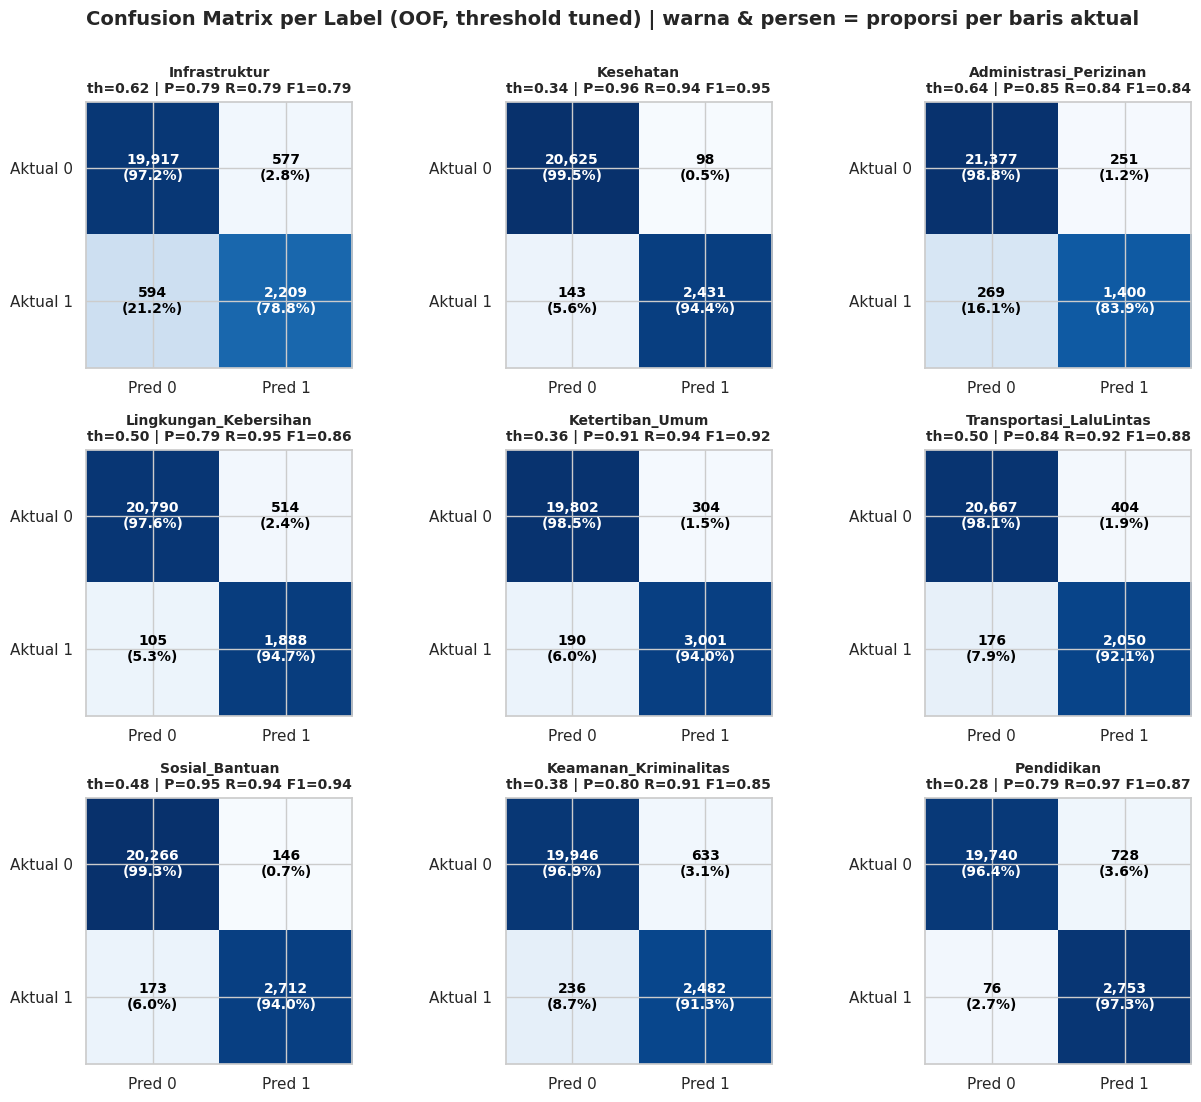

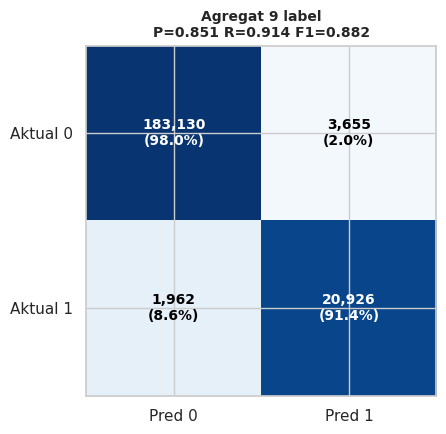

Label F1 terendah        : Infrastruktur (F1=0.790)
Recall terendah (FN besar): Infrastruktur (Recall=0.788, 594 positif terlewat)
Precision terendah (FP besar): Lingkungan_Kebersihan (Precision=0.786, 514 salah tandai)


In [14]:
from sklearn.metrics import multilabel_confusion_matrix
 
oof_final = (oof_ensemble >= np.asarray(best_thresholds)).astype(int)
cms = multilabel_confusion_matrix(y_train, oof_final)        # (9, 2, 2) -> [[TN, FP], [FN, TP]]
 
# ---------- Tabel ringkasan per label ----------
rows = []
for j, col in enumerate(target_cols):
    (tn, fp), (fn, tp) = cms[j]
    rows.append({
        'Label': col, 'Threshold': best_thresholds[j],
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Support(+)': tp + fn,
        'Precision': tp / max(tp + fp, 1),
        'Recall':    tp / max(tp + fn, 1),
        'F1':        2 * tp / max(2 * tp + fp + fn, 1),
        'Specificity': tn / max(tn + fp, 1),
    })
cm_df = pd.DataFrame(rows)
 
# Agregat (micro): jumlahkan semua label
TN, FP, FN, TP = cms[:, 0, 0].sum(), cms[:, 0, 1].sum(), cms[:, 1, 0].sum(), cms[:, 1, 1].sum()
micro_p = TP / max(TP + FP, 1); micro_r = TP / max(TP + FN, 1)
micro_f1_cm = 2 * TP / max(2 * TP + FP + FN, 1)
assert abs(micro_f1_cm - micro_f1) < 1e-9, "micro-F1 dari confusion matrix harus sama dengan sel 3.3"
 
pd.set_option('display.width', 200)
print(cm_df.round(4).to_string(index=False))
print(f"\nAGREGAT (micro, semua label digabung): TN={TN:,}  FP={FP:,}  FN={FN:,}  TP={TP:,}")
print(f"  Precision={micro_p:.4f}  Recall={micro_r:.4f}  Micro-F1={micro_f1_cm:.4f}  (cocok dengan sel 3.3: {micro_f1:.4f})")
print(f"  Macro-F1 (rata-rata F1 per label) = {cm_df['F1'].mean():.4f}")
 
# ---------- Heatmap per label (angka = jumlah baris; persen = proporsi dari baris kelas aktual) ----------
def draw_cm(ax, cm, title):
    pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f"{cm[r, c]:,}\n({pct[r, c]:.1f}%)", ha='center', va='center', fontsize=10,
                    color='white' if pct[r, c] > 50 else 'black', fontweight='bold')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred 0', 'Pred 1']); ax.set_yticklabels(['Aktual 0', 'Aktual 1'])
    ax.set_title(title, fontsize=10, fontweight='bold')
 
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for j, ax in enumerate(axes.ravel()):
    r = cm_df.iloc[j]
    draw_cm(ax, cms[j], f"{target_cols[j]}\nth={r['Threshold']:.2f} | P={r['Precision']:.2f} R={r['Recall']:.2f} F1={r['F1']:.2f}")
fig.suptitle('Confusion Matrix per Label (OOF, threshold tuned) | warna & persen = proporsi per baris aktual',
             fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()
 
# ---------- Heatmap agregat ----------
fig, ax = plt.subplots(figsize=(5.5, 4.5))
draw_cm(ax, np.array([[TN, FP], [FN, TP]]), f"Agregat 9 label\nP={micro_p:.3f} R={micro_r:.3f} F1={micro_f1_cm:.3f}")
plt.tight_layout(); plt.show()
 
# ---------- Ringkasan kesalahan ----------
worst_r = cm_df.loc[cm_df['Recall'].idxmin()]
worst_p = cm_df.loc[cm_df['Precision'].idxmin()]
worst_f = cm_df.loc[cm_df['F1'].idxmin()]
print(f"Label F1 terendah        : {worst_f['Label']} (F1={worst_f['F1']:.3f})")
print(f"Recall terendah (FN besar): {worst_r['Label']} (Recall={worst_r['Recall']:.3f}, {int(worst_r['FN'])} positif terlewat)")
print(f"Precision terendah (FP besar): {worst_p['Label']} (Precision={worst_p['Precision']:.3f}, {int(worst_p['FP'])} salah tandai)")

# 4. Submission

In [15]:
test_preds = (test_ensemble >= np.asarray(best_thresholds)).astype(int)
 
sub = pd.DataFrame(test_preds, columns=target_cols)
sub.insert(0, 'ID', test_df['ID'].values)
 
# Samakan dengan sample_submission (kolom, urutan baris, format nilai)
cols = list(submission_df.columns)
assert set(cols) == set(['ID'] + target_cols), f"Kolom sample_submission berbeda: {cols}"
assert sub['ID'].is_unique and set(sub['ID']) == set(submission_df['ID']), "ID test tidak cocok dengan sample_submission"
 
sample_val = submission_df[target_cols[0]].iloc[0]
if isinstance(sample_val, str) and sample_val.strip().lower() in ('relevan', 'tidak relevan'):
    print("✓ Format: String (Relevan/Tidak Relevan)")
    for col in target_cols:
        sub[col] = sub[col].map({1: 'Relevan', 0: 'Tidak Relevan'})      # Series.map, bukan ndarray.map
else:
    print("✓ Format: Binary (0/1)")
 
sub = sub.set_index('ID').loc[submission_df['ID']].reset_index()[cols]  # urutan ID = sample_submission
 
# Simpan file
submission_path = '/kaggle/working/submission.csv'
sub.to_csv(submission_path, index=False)
submission = sub
print(f"✓ File tersimpan: {submission_path}")
print(f"✓ Shape: {submission.shape}")
 
# Sanity check: laju positif prediksi test vs train (harus sebanding)
rate = pd.DataFrame({'%Positif train (asli)': y_train.mean(axis=0) * 100,
                     '%Positif test (prediksi)': test_preds.mean(axis=0) * 100}, index=target_cols).round(2)
print("\nLaju positif per label:")
print(rate.to_string())
 
print("\nPreview submission:")
print(submission.head())

✓ Format: Binary (0/1)
✓ File tersimpan: /kaggle/working/submission.csv
✓ Shape: (34687, 10)

Laju positif per label:
                         %Positif train (asli)  %Positif test (prediksi)
Infrastruktur                            12.03                     12.21
Kesehatan                                11.05                     12.64
Administrasi_Perizinan                    7.16                      5.07
Lingkungan_Kebersihan                     8.55                      9.21
Ketertiban_Umum                          13.70                     13.09
Transportasi_LaluLintas                   9.55                     11.72
Sosial_Bantuan                           12.38                     11.03
Keamanan_Kriminalitas                    11.67                     13.52
Pendidikan                               12.14                     15.01

Preview submission:
   ID  Infrastruktur  Kesehatan  Administrasi_Perizinan  Lingkungan_Kebersihan  Ketertiban_Umum  Transportasi_LaluLintas  Sosial_Ba

# 5. Perbandingan Dengan IndoBERT
## 5.1 Konfigurasi IndoBERT

In [16]:
import sys, subprocess, time
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel
 
# ---------------- KONFIGURASI ----------------
MODEL_NAME = 'indobenchmark/indobert-base-p1'   # alternatif: 'indolem/indobertweet-base-uncased' (dilatih pada tweet,
                                                #             lebih cocok untuk teks informal), 'indolem/indobert-base-uncased'
MAX_LEN    = 256            # token maksimum per teks (lebih panjang dipotong). Lihat statistik panjang di output.
BATCH_SIZE = 64
POOLING    = 'mean'         # 'mean' | 'cls' | 'mean+cls'
LAYERS     = (-1,)          # layer yang dipakai; mis. (-4, -3, -2, -1) = rata-rata 4 layer terakhir
DEMOJIZE   = True           # emoji -> teks, karena vocab BERT tidak punya emoji (akan menjadi [UNK])
CACHE_DIR  = '/kaggle/working/emb_cache'
 
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}" + ("" if device == 'cuda' else "  (CPU: ekstraksi akan JAUH lebih lambat, aktifkan GPU)"))
 
# ---------------- Emoji -> teks ----------------
_emoji = None
if DEMOJIZE:
    try:
        import emoji as _emoji
    except ImportError:
        try:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'emoji'], check=True)
            import emoji as _emoji
        except Exception as e:
            print(f"  ! paket 'emoji' tidak tersedia ({type(e).__name__}); emoji dibiarkan apa adanya.")
 
def prep_for_bert(s):
    if _emoji is not None:
        s = _emoji.replace_emoji(s, replace=lambda chars, data: ' ' + data['en'].strip(':').replace('_', ' ') + ' ')
        s = re.sub(r'\s+', ' ', s).strip()
    return s
 
bert_text_train = [prep_for_bert(t) for t in train_df['final_text']]
bert_text_test  = [prep_for_bert(t) for t in test_df['final_text']]
 
# ---------------- Muat model ----------------
print(f"Memuat {MODEL_NAME} ...")
try:
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
except Exception:
    from transformers import BertTokenizer
    tok = BertTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
H = bert.config.hidden_size
FEAT_DIM = H * (2 if POOLING == 'mean+cls' else 1)
print(f"  hidden_size={H} | dimensi fitur={FEAT_DIM} | pooling={POOLING} | layers={LAYERS}")
 
_tag = re.sub(r'[^A-Za-z0-9]+', '_', f"{MODEL_NAME}_{POOLING}_L{'_'.join(map(str, LAYERS))}_len{MAX_LEN}_emoji{int(_emoji is not None)}")
os.makedirs(CACHE_DIR, exist_ok=True)
 
@torch.no_grad()
def encode(texts, name):
    path = f"{CACHE_DIR}/{_tag}_{name}.npy"
    if os.path.exists(path):
        print(f"  [{name}] memuat cache: {path}")
        return np.load(path).astype(np.float32)
 
    ids = tok(texts, add_special_tokens=True, truncation=True, max_length=MAX_LEN, padding=False)['input_ids']
    lens = np.array([len(x) for x in ids])
    n_trunc = int((lens >= MAX_LEN).sum())
    print(f"  [{name}] panjang token: median={int(np.median(lens))}, p90={int(np.percentile(lens, 90))}, "
          f"p99={int(np.percentile(lens, 99))}, maks={lens.max()} | terpotong di {MAX_LEN}: {n_trunc:,} ({n_trunc/len(lens)*100:.1f}%)")
 
    out = np.zeros((len(texts), FEAT_DIM), dtype=np.float32)
    order = np.argsort(lens)                                   # urut panjang -> padding minimal -> jauh lebih cepat
    for s in tqdm(range(0, len(order), BATCH_SIZE), desc=f"encode {name}"):
        idx = order[s:s + BATCH_SIZE]
        b = tok.pad({'input_ids': [ids[i] for i in idx]}, return_tensors='pt')
        input_ids, attn = b['input_ids'].to(device), b['attention_mask'].to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
            if LAYERS == (-1,):
                hid = bert(input_ids=input_ids, attention_mask=attn).last_hidden_state
            else:
                hs = bert(input_ids=input_ids, attention_mask=attn, output_hidden_states=True).hidden_states
                hid = torch.stack([hs[l] for l in LAYERS]).mean(0)
        hid = hid.float()
        m = attn.unsqueeze(-1).float()
        mean = (hid * m).sum(1) / m.sum(1).clamp(min=1)       # rata-rata token NYATA (padding tidak ikut)
        cls = hid[:, 0]
        feat = mean if POOLING == 'mean' else cls if POOLING == 'cls' else torch.cat([mean, cls], dim=1)
        out[idx] = feat.cpu().numpy()
    np.save(path, out.astype(np.float16))                      # float16 -> separuh ukuran file
    return out
 
t0 = time.time()
emb_train = encode(bert_text_train, 'train')
emb_test  = encode(bert_text_test,  'test')
print(f"\n✓ Embedding train: {emb_train.shape} | test: {emb_test.shape} | waktu: {(time.time()-t0)/60:.1f} menit")
 
# ---------------- Sanity check ----------------
assert np.isfinite(emb_train).all() and np.isfinite(emb_test).all(), "ada NaN/Inf pada embedding"
print(f"  rata-rata std per dimensi: train={emb_train.std(0).mean():.4f}, test={emb_test.std(0).mean():.4f}")
print("  Contoh teks ke BERT :", bert_text_train[0][:120])
print("  Setelah tokenisasi  :", tok.decode(tok(bert_text_train[0], truncation=True, max_length=40)['input_ids']))

Device: cuda
Memuat indobenchmark/indobert-base-p1 ...


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

  hidden_size=768 | dimensi fitur=768 | pooling=mean | layers=(-1,)
  [train] panjang token: median=79, p90=191, p99=256, maks=256 | terpotong di 256: 1,266 (5.4%)


encode train:   0%|          | 0/365 [00:00<?, ?it/s]

  [test] panjang token: median=87, p90=248, p99=256, maks=256 | terpotong di 256: 3,270 (9.4%)


encode test:   0%|          | 0/542 [00:00<?, ?it/s]


✓ Embedding train: (23297, 768) | test: (34687, 768) | waktu: 1.4 menit
  rata-rata std per dimensi: train=0.3510, test=0.3557
  Contoh teks ke BERT : menteri hak asasi manusia (ham) natalius pigai melarang aparat kepolisian zrarzonx langsung pelaku begal di tempat. kata
  Setelah tokenisasi  : [CLS] menteri hak asasi manusia ( ham ) natalius pigai melarang aparat kepolisian zrarzonx langsung pelaku begal di tempat. kata dia, tindakan itu snujb melanggar hak asasi manusia. [SEP]


## 5.2 Percobaan pada IndoBERT 

In [17]:
import gc
from joblib import Parallel, delayed
from sklearn.preprocessing import StandardScaler

C_LR_BERT  = 0.1
C_SVM_BERT = 0.01
TUNE_C     = False

def _fit_lr(Xtr, ytr, Xs, C):
    m = LogisticRegression(C=C, max_iter=10000, class_weight='balanced', solver='lbfgs').fit(Xtr, ytr)
    return [m.predict_proba(X)[:, 1] for X in Xs]

def _fit_svm(Xtr, ytr, Xs, C):
    base = LinearSVC(C=C, class_weight='balanced', dual=False, max_iter=2000)
    m = CalibratedClassifierCV(base, cv=3, method='sigmoid').fit(Xtr, ytr)
    return [m.predict_proba(X)[:, 1] for X in Xs]
 
BERT_RUNS = globals().get('BERT_RUNS', {})        # registri: nama model -> hasil (dibaca sel 5.4)
WRITE_SUBMISSION = False                          # True: tulis submission_<model>.csv untuk tiap percobaan IndoBERT-saja
 
# ---------------- utilitas ----------------
def write_submission_file(P_test, thresholds, path):
    """Prediksi test -> CSV dengan format & urutan baris yang sama seperti sample_submission."""
    pred = (np.asarray(P_test) >= np.asarray(thresholds)).astype(int)
    sub = pd.DataFrame(pred, columns=target_cols)
    sub.insert(0, 'ID', test_df['ID'].values)
    cols = list(submission_df.columns)
    assert set(cols) == set(['ID'] + target_cols), f"Kolom sample_submission berbeda: {cols}"
    assert sub['ID'].is_unique and set(sub['ID']) == set(submission_df['ID']), "ID test tidak cocok dengan sample_submission"
    sv = submission_df[target_cols[0]].iloc[0]
    if isinstance(sv, str) and sv.strip().lower() in ('relevan', 'tidak relevan'):
        for c in target_cols:
            sub[c] = sub[c].map({1: 'Relevan', 0: 'Tidak Relevan'})
    sub = sub.set_index('ID').loc[submission_df['ID']].reset_index()[cols]
    sub.to_csv(path, index=False)
    print(f"  ✓ Tersimpan: {path}  | shape: {sub.shape}")
    return pred
 
def evaluate_bert_only(name, o_lr, o_svm, t_lr, t_svm):
    """P = wb*LR + (1-wb)*SVM (wb dicari), threshold per label di-tuning, hasil disimpan di BERT_RUNS[name]."""
    best = None
    for wb in (0.0, 0.25, 0.5, 0.75, 1.0):
        ths, f1s, mi, ma = tune_thresholds(y_train, wb * o_lr + (1 - wb) * o_svm)
        sc = mi if OBJECTIVE == 'micro' else ma
        if best is None or sc > best[0]:
            best = (sc, wb, ths, f1s, mi, ma)
    _, wb, ths, f1s, mi, ma = best
    _, _, mi_l, ma_l = tune_thresholds(y_train, o_lr)
    _, _, mi_s, ma_s = tune_thresholds(y_train, o_svm)
 
    BERT_RUNS[name] = {'wb': wb, 'oof_lr': o_lr, 'oof_svm': o_svm, 'test_lr': t_lr, 'test_svm': t_svm,
                       'oof': wb * o_lr + (1 - wb) * o_svm, 'test': wb * t_lr + (1 - wb) * t_svm,
                       'thresholds': ths, 'f1_label': f1s, 'micro': mi, 'macro': ma}
 
    print(f"\n>>> {name}  |  IndoBERT SAJA (tanpa TF-IDF)  |  OOF, threshold tuned per label")
    print(pd.DataFrame([
        {'Model': 'LR (IndoBERT)',                 'Micro-F1': mi_l, 'Macro-F1': ma_l},
        {'Model': 'SVM (IndoBERT)',                'Micro-F1': mi_s, 'Macro-F1': ma_s},
        {'Model': f'Blend LR+SVM (wb={wb:.2f})',   'Micro-F1': mi,   'Macro-F1': ma},
        {'Model': '(pembanding) Ensemble TF-IDF',  'Micro-F1': micro_f1, 'Macro-F1': macro_f1},
    ]).round(4).to_string(index=False))
    print(f"Selisih blend IndoBERT vs TF-IDF: micro {mi - micro_f1:+.4f} | macro {ma - macro_f1:+.4f}")
    print(pd.DataFrame({'Label': target_cols, 'F1 TF-IDF': f1_per_label, 'F1 IndoBERT': f1s,
                        'Selisih': f1s - f1_per_label, 'Threshold': ths}).round(4).to_string(index=False))
    if WRITE_SUBMISSION:
        write_submission_file(BERT_RUNS[name]['test'], ths, f"/kaggle/working/submission_{re.sub(r'[^A-Za-z0-9]+', '_', name)}.csv")
 
def _model_tag(model_name):    # rumus sama dengan sel 5.1 -> cache embedding dipakai bersama
    return re.sub(r'[^A-Za-z0-9]+', '_', f"{model_name}_{POOLING}_L{'_'.join(map(str, LAYERS))}_len{MAX_LEN}_emoji{int(_emoji is not None)}")
 
@torch.no_grad()
def _encode(tk, mdl, texts, feat_dim, desc):
    ids = tk(texts, add_special_tokens=True, truncation=True, max_length=MAX_LEN, padding=False)['input_ids']
    lens = np.array([len(x) for x in ids]); n_trunc = int((lens >= MAX_LEN).sum())
    print(f"  [{desc}] panjang token: median={int(np.median(lens))}, p90={int(np.percentile(lens, 90))}, "
          f"maks={lens.max()} | terpotong di {MAX_LEN}: {n_trunc:,} ({n_trunc/len(lens)*100:.1f}%)")
    out = np.zeros((len(texts), feat_dim), dtype=np.float32)
    order = np.argsort(lens)
    for s in tqdm(range(0, len(order), BATCH_SIZE), desc=f"encode {desc}"):
        idx = order[s:s + BATCH_SIZE]
        b = tk.pad({'input_ids': [ids[i] for i in idx]}, return_tensors='pt')
        input_ids, attn = b['input_ids'].to(device), b['attention_mask'].to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
            if LAYERS == (-1,):
                hid = mdl(input_ids=input_ids, attention_mask=attn).last_hidden_state
            else:
                hs = mdl(input_ids=input_ids, attention_mask=attn, output_hidden_states=True).hidden_states
                hid = torch.stack([hs[l] for l in LAYERS]).mean(0)
        hid = hid.float(); m = attn.unsqueeze(-1).float()
        mean = (hid * m).sum(1) / m.sum(1).clamp(min=1)
        feat = mean if POOLING == 'mean' else hid[:, 0] if POOLING == 'cls' else torch.cat([mean, hid[:, 0]], dim=1)
        out[idx] = feat.cpu().numpy()
    return out
 
def _extract_embeddings(model_name):
    tag = _model_tag(model_name)
    paths = {s: f"{CACHE_DIR}/{tag}_{s}.npy" for s in ('train', 'test')}
    if all(os.path.exists(p) for p in paths.values()):
        print("  embedding dimuat dari cache"); return [np.load(paths[s]).astype(np.float32) for s in ('train', 'test')]
    print(f"  memuat {model_name} ...")
    try:
        tk = AutoTokenizer.from_pretrained(model_name)
    except Exception:
        from transformers import BertTokenizer
        tk = BertTokenizer.from_pretrained(model_name)
    mdl = AutoModel.from_pretrained(model_name).to(device).eval()
    feat_dim = mdl.config.hidden_size * (2 if POOLING == 'mean+cls' else 1)
    outs = []
    for s, texts in (('train', bert_text_train), ('test', bert_text_test)):
        e = _encode(tk, mdl, texts, feat_dim, s)
        np.save(paths[s], e.astype(np.float16)); outs.append(e)
    del mdl, tk; gc.collect()
    if device == 'cuda': torch.cuda.empty_cache()
    return outs
 
def _train_heads(E_all, E_te):
    """LR + SVM terkalibrasi per label, fold sama dengan sel 3.1 (split_iter). Memakai _fit_lr/_fit_svm dari sel 5.2."""
    o_lr = np.zeros((len(y_train), N_LABELS)); o_svm = np.zeros_like(o_lr)
    t_lr = np.zeros((len(E_te), N_LABELS));    t_svm = np.zeros_like(t_lr)
    for fold, (tr_idx, val_idx) in enumerate(split_iter):
        print(f"  fold {fold + 1}/{N_FOLDS} ...")
        sc = StandardScaler().fit(E_all[tr_idx])
        Etr, Eval, Ete = (sc.transform(E_all[tr_idx]).astype(np.float32),
                          sc.transform(E_all[val_idx]).astype(np.float32), sc.transform(E_te).astype(np.float32))
        ytr = y_train[tr_idx]
        for fit, o, t, C in ((_fit_lr, o_lr, t_lr, C_LR_BERT), (_fit_svm, o_svm, t_svm, C_SVM_BERT)):
            res = Parallel(n_jobs=-1)(delayed(fit)(Etr, ytr[:, j], [Eval, Ete], C) for j in range(N_LABELS))
            for j, (pv, pt) in enumerate(res):
                o[val_idx, j] = pv; t[:, j] += pt / N_FOLDS
    return o_lr, o_svm, t_lr, t_svm
 
def run_bert_experiment(model_name):
    """Satu model IndoBERT end-to-end: embedding (cache) -> LR+SVM per fold -> blend -> threshold -> BERT_RUNS."""
    t0 = time.time()
    print(f"\n{'=' * 78}\n{model_name}\n{'=' * 78}")
    E_tr, E_te = _extract_embeddings(model_name)
    print(f"  embedding: train {E_tr.shape} | test {E_te.shape}")
    evaluate_bert_only(model_name, *_train_heads(E_tr, E_te))
    print(f"\n✓ {model_name} selesai dalam {(time.time() - t0) / 60:.1f} menit")

## 5.3 Percobaan IndoBERT Tweet

In [18]:
run_bert_experiment('indolem/indobertweet-base-uncased')


indolem/indobertweet-base-uncased
  memuat indolem/indobertweet-base-uncased ...


config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/235k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

  [train] panjang token: median=77, p90=185, maks=256 | terpotong di 256: 1,170 (5.0%)


encode train:   0%|          | 0/365 [00:00<?, ?it/s]

  [test] panjang token: median=85, p90=247, maks=256 | terpotong di 256: 3,091 (8.9%)


encode test:   0%|          | 0/542 [00:00<?, ?it/s]

  embedding: train (23297, 768) | test (34687, 768)
  fold 1/5 ...
  fold 2/5 ...
  fold 3/5 ...
  fold 4/5 ...
  fold 5/5 ...

>>> indolem/indobertweet-base-uncased  |  IndoBERT SAJA (tanpa TF-IDF)  |  OOF, threshold tuned per label
                       Model  Micro-F1  Macro-F1
               LR (IndoBERT)    0.8643    0.8611
              SVM (IndoBERT)    0.8684    0.8653
      Blend LR+SVM (wb=0.25)    0.8689    0.8656
(pembanding) Ensemble TF-IDF    0.8817    0.8793
Selisih blend IndoBERT vs TF-IDF: micro -0.0128 | macro -0.0138
                  Label  F1 TF-IDF  F1 IndoBERT  Selisih  Threshold
          Infrastruktur     0.7905       0.7809  -0.0096       0.56
              Kesehatan     0.9528       0.9426  -0.0102       0.52
 Administrasi_Perizinan     0.8434       0.8227  -0.0207       0.56
  Lingkungan_Kebersihan     0.8592       0.8478  -0.0114       0.44
        Ketertiban_Umum     0.9240       0.9118  -0.0122       0.58
Transportasi_LaluLintas     0.8761       0.8544  

## 5.4 Percobaan IndoBERT-base-uncased

In [19]:
run_bert_experiment('indolem/indobert-base-uncased')


indolem/indobert-base-uncased
  memuat indolem/indobert-base-uncased ...


config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/234k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

...

  [train] panjang token: median=81, p90=194, maks=256 | terpotong di 256: 1,380 (5.9%)


encode train:   0%|          | 0/365 [00:00<?, ?it/s]

  [test] panjang token: median=90, p90=251, maks=256 | terpotong di 256: 3,358 (9.7%)


encode test:   0%|          | 0/542 [00:00<?, ?it/s]

  embedding: train (23297, 768) | test (34687, 768)
  fold 1/5 ...
  fold 2/5 ...
  fold 3/5 ...
  fold 4/5 ...
  fold 5/5 ...

>>> indolem/indobert-base-uncased  |  IndoBERT SAJA (tanpa TF-IDF)  |  OOF, threshold tuned per label
                       Model  Micro-F1  Macro-F1
               LR (IndoBERT)    0.8426    0.8388
              SVM (IndoBERT)    0.8490    0.8449
      Blend LR+SVM (wb=0.00)    0.8490    0.8449
(pembanding) Ensemble TF-IDF    0.8817    0.8793
Selisih blend IndoBERT vs TF-IDF: micro -0.0326 | macro -0.0344
                  Label  F1 TF-IDF  F1 IndoBERT  Selisih  Threshold
          Infrastruktur     0.7905       0.7573  -0.0332       0.48
              Kesehatan     0.9528       0.9287  -0.0241       0.46
 Administrasi_Perizinan     0.8434       0.7905  -0.0528       0.36
  Lingkungan_Kebersihan     0.8592       0.8165  -0.0426       0.32
        Ketertiban_Umum     0.9240       0.9056  -0.0183       0.46
Transportasi_LaluLintas     0.8761       0.8295  -0.0

## 5.5 Klasifikasi Di atas Embedding IndoBERT

In [20]:
def _scaled_fold(tr_idx, val_idx):
    sc = StandardScaler().fit(emb_train[tr_idx])                 # scaler hanya melihat data latih fold ini
    return (sc.transform(emb_train[tr_idx]).astype(np.float32),
            sc.transform(emb_train[val_idx]).astype(np.float32),
            sc.transform(emb_test).astype(np.float32))
 
# ---------- (opsional) cari C untuk LR ----------
if TUNE_C:
    tr0, va0 = split_iter[0]
    A, B, _ = _scaled_fold(tr0, va0)
    print("Cari C (LR, fold 1) | skor = micro-F1 dengan threshold per label di-tuning")
    best_c, best_s = None, -1
    for c in (0.01, 0.03, 0.1, 0.3, 1.0):
        res = Parallel(n_jobs=-1)(delayed(_fit_lr)(A, y_train[tr0, j], [B], c) for j in range(N_LABELS))
        Pv = np.stack([r[0] for r in res], axis=1)
        s = tune_thresholds(y_train[va0], Pv)[2]
        print(f"  C={c:<5} micro-F1={s:.4f}")
        if s > best_s: best_c, best_s = c, s
    C_LR_BERT, C_SVM_BERT = best_c, best_c / 10
    print(f"-> dipakai: C_LR_BERT={C_LR_BERT}, C_SVM_BERT={C_SVM_BERT}")
 
oof_lr_b  = np.zeros((len(y_train), N_LABELS)); oof_svm_b  = np.zeros_like(oof_lr_b)
test_lr_b = np.zeros((len(emb_test), N_LABELS)); test_svm_b = np.zeros_like(test_lr_b)
 
t0 = time.time()
for fold, (tr_idx, val_idx) in enumerate(split_iter):
    print(f"\n--- Fold {fold + 1}/{N_FOLDS} (BERT features) ---")
    Etr, Eval, Ete = _scaled_fold(tr_idx, val_idx)
    ytr, yva = y_train[tr_idx], y_train[val_idx]
 
    res = Parallel(n_jobs=-1)(delayed(_fit_lr)(Etr, ytr[:, j], [Eval, Ete], C_LR_BERT) for j in range(N_LABELS))
    for j, (pv, pt) in enumerate(res):
        oof_lr_b[val_idx, j] = pv; test_lr_b[:, j] += pt / N_FOLDS
 
    res = Parallel(n_jobs=-1)(delayed(_fit_svm)(Etr, ytr[:, j], [Eval, Ete], C_SVM_BERT) for j in range(N_LABELS))
    for j, (pv, pt) in enumerate(res):
        oof_svm_b[val_idx, j] = pv; test_svm_b[:, j] += pt / N_FOLDS
 
    for nm, oo in (('LR-BERT', oof_lr_b), ('SVM-BERT', oof_svm_b)):
        f = f1_score(yva, (oo[val_idx] >= 0.5).astype(int), average='micro', zero_division=0)
        print(f"  Fold {fold + 1} {nm:<8s} Micro-F1 (th=0.5): {f:.4f}")
 
print(f"\n✓ Selesai dalam {(time.time()-t0)/60:.1f} menit")
 
# ---------- Perbandingan semua model (threshold per label di-tuning untuk masing-masing) ----------
rows = []
for nm, P in (('LR (TF-IDF)', oof_lr), ('NBSVM (TF-IDF)', oof_nb), ('SVM (TF-IDF)', oof_svm),
              ('Ensemble TF-IDF (sel 3.2)', oof_ensemble),
              ('LR (IndoBERT)', oof_lr_b), ('SVM (IndoBERT)', oof_svm_b)):
    _, _, mi, ma = tune_thresholds(y_train, P)
    rows.append({'Model': nm, 'Micro-F1': round(mi, 4), 'Macro-F1': round(ma, 4)})
print("\nOOF, threshold tuned per label:")
print(pd.DataFrame(rows).to_string(index=False))


--- Fold 1/5 (BERT features) ---
  Fold 1 LR-BERT  Micro-F1 (th=0.5): 0.8421
  Fold 1 SVM-BERT Micro-F1 (th=0.5): 0.8685

--- Fold 2/5 (BERT features) ---
  Fold 2 LR-BERT  Micro-F1 (th=0.5): 0.8359
  Fold 2 SVM-BERT Micro-F1 (th=0.5): 0.8631

--- Fold 3/5 (BERT features) ---
  Fold 3 LR-BERT  Micro-F1 (th=0.5): 0.8374
  Fold 3 SVM-BERT Micro-F1 (th=0.5): 0.8653

--- Fold 4/5 (BERT features) ---
  Fold 4 LR-BERT  Micro-F1 (th=0.5): 0.8427
  Fold 4 SVM-BERT Micro-F1 (th=0.5): 0.8655

--- Fold 5/5 (BERT features) ---
  Fold 5 LR-BERT  Micro-F1 (th=0.5): 0.8372
  Fold 5 SVM-BERT Micro-F1 (th=0.5): 0.8628

✓ Selesai dalam 4.8 menit

OOF, threshold tuned per label:
                    Model  Micro-F1  Macro-F1
              LR (TF-IDF)    0.8775    0.8749
           NBSVM (TF-IDF)    0.8796    0.8774
             SVM (TF-IDF)    0.8810    0.8791
Ensemble TF-IDF (sel 3.2)    0.8817    0.8793
            LR (IndoBERT)    0.8643    0.8610
           SVM (IndoBERT)    0.8671    0.8645


In [21]:
evaluate_bert_only(MODEL_NAME, oof_lr_b, oof_svm_b, test_lr_b, test_svm_b)


>>> indobenchmark/indobert-base-p1  |  IndoBERT SAJA (tanpa TF-IDF)  |  OOF, threshold tuned per label
                       Model  Micro-F1  Macro-F1
               LR (IndoBERT)    0.8643    0.8610
              SVM (IndoBERT)    0.8671    0.8645
      Blend LR+SVM (wb=0.00)    0.8671    0.8645
(pembanding) Ensemble TF-IDF    0.8817    0.8793
Selisih blend IndoBERT vs TF-IDF: micro -0.0145 | macro -0.0148
                  Label  F1 TF-IDF  F1 IndoBERT  Selisih  Threshold
          Infrastruktur     0.7905       0.7742  -0.0163       0.42
              Kesehatan     0.9528       0.9432  -0.0096       0.48
 Administrasi_Perizinan     0.8434       0.8228  -0.0206       0.44
  Lingkungan_Kebersihan     0.8592       0.8410  -0.0182       0.36
        Ketertiban_Umum     0.9240       0.9135  -0.0105       0.50
Transportasi_LaluLintas     0.8761       0.8562  -0.0199       0.40
         Sosial_Bantuan     0.9445       0.9226  -0.0218       0.50
  Keamanan_Kriminalitas     0.8510       0.

## 5.6 Ensembling dengan TF-IDF

In [22]:
results = []
for wb in (0.0, 0.25, 0.5, 0.75, 1.0):
    Pb = wb * oof_lr_b + (1 - wb) * oof_svm_b
    for a in np.round(np.arange(0.0, 1.0001, 0.1), 2):
        P = (1 - a) * oof_ensemble + a * Pb
        _, _, mi, ma = tune_thresholds(y_train, P)
        results.append({'a (bobot BERT)': a, 'wb (LR vs SVM)': wb, 'micro': mi, 'macro': ma})
hyb_df = pd.DataFrame(results).sort_values(OBJECTIVE, ascending=False).reset_index(drop=True)
best_h = hyb_df.iloc[0]
a_best, wb_best = float(best_h['a (bobot BERT)']), float(best_h['wb (LR vs SVM)'])
 
print(f"Objektif: {OBJECTIVE}-F1 (threshold per label di-tuning)")
print("\nTop-5 kombinasi:"); print(hyb_df.head(5).round(4).to_string(index=False))
base = hyb_df[hyb_df['a (bobot BERT)'] == 0.0].iloc[0]
only = hyb_df[hyb_df['a (bobot BERT)'] == 1.0].sort_values(OBJECTIVE, ascending=False).iloc[0]
print(f"\nPembanding -> hanya TF-IDF : micro={base['micro']:.4f} macro={base['macro']:.4f}")
print(f"           -> hanya IndoBERT: micro={only['micro']:.4f} macro={only['macro']:.4f}")
print(f"\n✓ Terpilih: a={a_best:.1f}, wb={wb_best:.2f}  ->  micro={best_h['micro']:.4f}, macro={best_h['macro']:.4f}"
      f"  (selisih vs TF-IDF saja: {best_h[OBJECTIVE] - base[OBJECTIVE]:+.4f})")
 
# ---------- Threshold per label untuk model hibrida ----------
P_b_oof   = wb_best * oof_lr_b  + (1 - wb_best) * oof_svm_b
P_b_test  = wb_best * test_lr_b + (1 - wb_best) * test_svm_b
oof_hybrid  = (1 - a_best) * oof_ensemble  + a_best * P_b_oof
test_hybrid = (1 - a_best) * test_ensemble + a_best * P_b_test
hyb_thresholds, hyb_f1_label, hyb_micro, hyb_macro = tune_thresholds(y_train, oof_hybrid)
 
cmp = pd.DataFrame({'Label': target_cols,
                    'F1 TF-IDF': f1_per_label, 'F1 Hybrid': hyb_f1_label,
                    'Selisih': hyb_f1_label - f1_per_label,
                    'Th TF-IDF': best_thresholds, 'Th Hybrid': hyb_thresholds}).round(4)
print("\nPer label:"); print(cmp.to_string(index=False))
print(f"\nMicro-F1: {micro_f1:.4f} -> {hyb_micro:.4f} | Macro-F1: {macro_f1:.4f} -> {hyb_macro:.4f}")
 
# ---------- Uji konsistensi per fold (apakah hibrida menang di semua fold, bukan hanya rata-rata?) ----------
def _micro_at(Y, P, ths):
    pr = (P >= ths).astype(int)
    tp = (pr & Y).sum(); fp = pr.sum() - tp; fn = Y.sum() - tp
    return 2 * tp / max(2 * tp + fp + fn, 1)
 
wins = 0
print("\nMicro-F1 per fold (threshold tetap dari OOF penuh):")
for k, (_, va) in enumerate(split_iter):
    f_old = _micro_at(y_train[va], oof_ensemble[va], best_thresholds)
    f_new = _micro_at(y_train[va], oof_hybrid[va], hyb_thresholds)
    wins += f_new > f_old
    print(f"  Fold {k+1}: TF-IDF={f_old:.4f}  Hybrid={f_new:.4f}  ({f_new - f_old:+.4f})")
print(f"Hybrid lebih baik di {wins}/{N_FOLDS} fold.")
print("Catatan: bobot & threshold dipilih dari OOF yang sama -> selisih kecil (< ~0.002) sebaiknya dianggap setara,")
print("dan hibrida yang menang di semua fold lebih meyakinkan daripada yang menang hanya di rata-rata.")
 
# ---------- Submission hibrida (file TERPISAH; submission.csv lama tidak ditimpa) ----------
test_preds_h = (test_hybrid >= hyb_thresholds).astype(int)
sub_h = pd.DataFrame(test_preds_h, columns=target_cols)
sub_h.insert(0, 'ID', test_df['ID'].values)
 
cols = list(submission_df.columns)
assert set(cols) == set(['ID'] + target_cols), f"Kolom sample_submission berbeda: {cols}"
assert sub_h['ID'].is_unique and set(sub_h['ID']) == set(submission_df['ID']), "ID test tidak cocok dengan sample_submission"
 
sample_val = submission_df[target_cols[0]].iloc[0]
if isinstance(sample_val, str) and sample_val.strip().lower() in ('relevan', 'tidak relevan'):
    for col in target_cols:
        sub_h[col] = sub_h[col].map({1: 'Relevan', 0: 'Tidak Relevan'})
sub_h = sub_h.set_index('ID').loc[submission_df['ID']].reset_index()[cols]
 
hybrid_path = '/kaggle/working/submission_indobert_hybrid.csv'
sub_h.to_csv(hybrid_path, index=False)
print(f"\n✓ Tersimpan: {hybrid_path}  | shape: {sub_h.shape}")
 
rate = pd.DataFrame({'%Positif train (asli)':     y_train.mean(axis=0) * 100,
                     '%Positif test (TF-IDF)':    (test_ensemble >= best_thresholds).mean(axis=0) * 100,
                     '%Positif test (Hybrid)':    test_preds_h.mean(axis=0) * 100}, index=target_cols).round(2)
print("\nLaju positif per label:"); print(rate.to_string())

Objektif: micro-F1 (threshold per label di-tuning)

Top-5 kombinasi:
 a (bobot BERT)  wb (LR vs SVM)  micro  macro
            0.2            0.25 0.8829 0.8805
            0.2            0.00 0.8828 0.8804
            0.3            0.50 0.8826 0.8804
            0.2            0.50 0.8826 0.8802
            0.3            0.75 0.8825 0.8803

Pembanding -> hanya TF-IDF : micro=0.8817 macro=0.8793
           -> hanya IndoBERT: micro=0.8671 macro=0.8645

✓ Terpilih: a=0.2, wb=0.25  ->  micro=0.8829, macro=0.8805  (selisih vs TF-IDF saja: +0.0012)

Per label:
                  Label  F1 TF-IDF  F1 Hybrid  Selisih  Th TF-IDF  Th Hybrid
          Infrastruktur     0.7905     0.7935   0.0030       0.62       0.60
              Kesehatan     0.9528     0.9549   0.0022       0.34       0.28
 Administrasi_Perizinan     0.8434     0.8425  -0.0009       0.64       0.62
  Lingkungan_Kebersihan     0.8592     0.8592   0.0001       0.50       0.42
        Ketertiban_Umum     0.9240     0.9242   0.0

## 5.7 Ensembling Semuanya

In [23]:
# %% ===== SEL BARU 5.4 Gabungan akhir (taruh SETELAH 5.3) =====
# 5.4 GABUNGAN AKHIR: TF-IDF + SEMUA INDOBERT (dan pembanding TF-IDF saja / IndoBERT saja)
#
# Komponen = ensemble TF-IDF (sel 3.2) + blend LR/SVM tiap model IndoBERT yang ada di BERT_RUNS (sel 5.2b-5.2d).
# Konfigurasi yang dibandingkan (semua: threshold per label di-tuning, skor OOF):
#   1. TF-IDF saja                         4. TF-IDF + semua IndoBERT, IndoBERT dirata-rata, cari 1 bobot 'a'   (2 parameter, lebih aman)
#   2. tiap IndoBERT saja                  5. TF-IDF + tiap IndoBERT dengan bobot sendiri-sendiri (simpleks 0.1) (lebih fleksibel, lebih rawan overfit ke OOF)
#   3. semua IndoBERT saja (rata-rata)
import itertools
 
USE_FULL_SIMPLEX = False      # False -> submission memakai konfigurasi 4; True -> konfigurasi 5
WRITE_FINAL      = True
 
names = list(BERT_RUNS.keys()); K = len(names)
assert K >= 1, "BERT_RUNS kosong: jalankan sel 5.2b (dan 5.2c, 5.2d) terlebih dahulu"
short = [n.split('/')[-1] for n in names]
O_b = [BERT_RUNS[n]['oof'] for n in names]
T_b = [BERT_RUNS[n]['test'] for n in names]
key = 'micro' if OBJECTIVE == 'micro' else 'macro'
print(f"Komponen: TF-IDF + {K} IndoBERT -> {short}")
 
def _eval(P):
    ths, f1s, mi, ma = tune_thresholds(y_train, P)
    return ths, f1s, mi, ma, (mi if key == 'micro' else ma)
 
rows = [{'Konfigurasi': '1. TF-IDF saja', 'micro': micro_f1, 'macro': macro_f1}]
for n, s in zip(names, short):
    rows.append({'Konfigurasi': f'2. {s} saja', 'micro': BERT_RUNS[n]['micro'], 'macro': BERT_RUNS[n]['macro']})
 
P_avg_oof, P_avg_test = np.mean(O_b, axis=0), np.mean(T_b, axis=0)
_, _, mi, ma, _ = _eval(P_avg_oof)
rows.append({'Konfigurasi': '3. Semua IndoBERT saja (rata-rata)', 'micro': mi, 'macro': ma})
 
# ---- Konfigurasi 4: TF-IDF + rata-rata IndoBERT ----
best4 = None
for a in np.round(np.arange(0.0, 1.0001, 0.05), 2):
    _, _, mi, ma, s = _eval((1 - a) * oof_ensemble + a * P_avg_oof)
    if best4 is None or s > best4[0]: best4 = (s, a, mi, ma)
a_avg = float(best4[1])
rows.append({'Konfigurasi': f'4. TF-IDF + semua IndoBERT (rata-rata, a={a_avg:.2f})', 'micro': best4[2], 'macro': best4[3]})
W4 = [1 - a_avg] + [a_avg / K] * K
 
# ---- Konfigurasi 5: bobot per komponen, simpleks langkah 0.1 ----
def compositions(total, parts):
    for c in itertools.combinations(range(total + parts - 1), parts - 1):
        prev, out = -1, []
        for x in c:
            out.append(x - prev - 1); prev = x
        out.append(total + parts - 2 - prev)
        yield out
 
comps_oof = [oof_ensemble] + O_b
comps_test = [test_ensemble] + T_b
best5 = None
for w in compositions(10, K + 1):
    wv = [x / 10 for x in w]
    _, _, mi, ma, s = _eval(sum(wi * Pi for wi, Pi in zip(wv, comps_oof)))
    if best5 is None or s > best5[0]: best5 = (s, wv, mi, ma)
W5 = best5[1]
rows.append({'Konfigurasi': '5. TF-IDF + tiap IndoBERT (bobot sendiri-sendiri)', 'micro': best5[2], 'macro': best5[3]})
 
res = pd.DataFrame(rows)
res['Selisih vs TF-IDF'] = (res[key] - micro_f1 if key == 'micro' else res[key] - macro_f1).round(4)
print(f"\nRingkasan (OOF, {key}-F1 sebagai acuan urutan):")
print(res.sort_values(key, ascending=False).round(4).to_string(index=False))
lab = ['TF-IDF'] + short
print("\nBobot konfigurasi 4:", {l: round(w, 3) for l, w in zip(lab, W4)})
print("Bobot konfigurasi 5:", {l: round(w, 3) for l, w in zip(lab, W5)})
 
# ---- Konfigurasi yang dipakai untuk submission ----
W = W5 if USE_FULL_SIMPLEX else W4
oof_blend  = sum(w * P for w, P in zip(W, comps_oof))
test_blend = sum(w * P for w, P in zip(W, comps_test))
fin_ths, fin_f1, fin_micro, fin_macro, _ = _eval(oof_blend)
print(f"\n✓ Dipakai untuk submission: konfigurasi {'5' if USE_FULL_SIMPLEX else '4'} "
      f"-> micro={fin_micro:.4f}, macro={fin_macro:.4f} (TF-IDF saja: {micro_f1:.4f} / {macro_f1:.4f})")
 
print("\nPer label:")
print(pd.DataFrame({'Label': target_cols, 'F1 TF-IDF': f1_per_label, 'F1 Gabungan': fin_f1,
                    'Selisih': fin_f1 - f1_per_label, 'Th TF-IDF': best_thresholds, 'Th Gabungan': fin_ths}).round(4).to_string(index=False))
 
# ---- Konsistensi per fold ----
def _micro_at(Y, P, ths):
    pr = (P >= ths).astype(int); tp = (pr & Y).sum(); fp = pr.sum() - tp; fn = Y.sum() - tp
    return 2 * tp / max(2 * tp + fp + fn, 1)
 
wins = 0
print("\nMicro-F1 per fold (threshold tetap dari OOF penuh):")
for k, (_, va) in enumerate(split_iter):
    f_old = _micro_at(y_train[va], oof_ensemble[va], best_thresholds)
    f_new = _micro_at(y_train[va], oof_blend[va], fin_ths)
    wins += f_new > f_old
    print(f"  Fold {k + 1}: TF-IDF={f_old:.4f}  Gabungan={f_new:.4f}  ({f_new - f_old:+.4f})")
print(f"Gabungan lebih baik di {wins}/{N_FOLDS} fold.")
print("Catatan: makin banyak konfigurasi yang dibandingkan pada OOF yang sama, makin besar kemungkinan skor terbaik")
print("sedikit kebetulan. Selisih < ~0.002 sebaiknya dianggap setara; menangnya konsisten di semua fold lebih meyakinkan.")
 
if WRITE_FINAL:
    pred = write_submission_file(test_blend, fin_ths, '/kaggle/working/submission_final_blend.csv')
    print(pd.DataFrame({'%Positif train (asli)': y_train.mean(axis=0) * 100,
                        '%Positif test (TF-IDF)': (test_ensemble >= best_thresholds).mean(axis=0) * 100,
                        '%Positif test (Gabungan)': pred.mean(axis=0) * 100}, index=target_cols).round(2).to_string())

Komponen: TF-IDF + 3 IndoBERT -> ['indobertweet-base-uncased', 'indobert-base-uncased', 'indobert-base-p1']

Ringkasan (OOF, micro-F1 sebagai acuan urutan):
                                      Konfigurasi  micro  macro  Selisih vs TF-IDF
5. TF-IDF + tiap IndoBERT (bobot sendiri-sendiri) 0.8839 0.8817             0.0023
   4. TF-IDF + semua IndoBERT (rata-rata, a=0.35) 0.8832 0.8809             0.0015
                                   1. TF-IDF saja 0.8817 0.8793             0.0000
               3. Semua IndoBERT saja (rata-rata) 0.8775 0.8744            -0.0042
                2. indobertweet-base-uncased saja 0.8689 0.8656            -0.0128
                         2. indobert-base-p1 saja 0.8671 0.8645            -0.0145
                    2. indobert-base-uncased saja 0.8490 0.8449            -0.0326

Bobot konfigurasi 4: {'TF-IDF': 0.65, 'indobertweet-base-uncased': 0.117, 'indobert-base-uncased': 0.117, 'indobert-base-p1': 0.117}
Bobot konfigurasi 5: {'TF-IDF': 0.6, 'indober

## 5.8 Modified Extraction

In [24]:
# %% ===== SEL BARU 5.4b Early Fusion: taruh SETELAH sel 5.4 dan SEBELUM sel 5.5 =====
# 5.4b EARLY FUSION: TF-IDF + SEMUA INDOBERT digabung jadi SATU ruang fitur, baru classifier dilatih
#
# Beda dengan sel 5.3/5.4 (late fusion):
#   late fusion : tiap representasi punya classifier sendiri -> probabilitasnya digabung.
#   early fusion: fitur TF-IDF + 3 embedding IndoBERT di-CONCAT -> SATU LR dan SATU SVM belajar dari semuanya sekaligus.
#
# Perlakuan skala (penting, tanpa ini blok BERT yang padat akan menenggelamkan TF-IDF):
#   - blok TF-IDF dibiarkan persis seperti sel 3.1 (hasil sebanding dengan baseline TF-IDF)
#   - tiap embedding IndoBERT: StandardScaler -> normalisasi L2 per baris (norma 1) -> dikali BETA
# NBSVM TIDAK dipakai: rasio Naive Bayes mengandaikan fitur non-negatif, sedangkan embedding bernilai negatif.
#
# Butuh sel 5.2b (fungsi _extract_embeddings, write_submission_file) dan embedding ketiga model (cache dari 5.1/5.2b-5.2d).
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import normalize
 
# ---------------- KONFIGURASI ----------------
EF_MODELS = ['indobenchmark/indobert-base-p1',
             'indolem/indobertweet-base-uncased',
             'indolem/indobert-base-uncased']
BETA       = 1.0        # bobot tiap blok IndoBERT (1.0 = norma baris blok IndoBERT sama dengan 1; >1 -> BERT lebih berpengaruh)
C_LR_EF    = 1.0        # sama dengan LR TF-IDF di sel 3.1
C_SVM_EF   = 1.0        # sama dengan SVM TF-IDF di sel 3.1
N_JOBS_EF  = -1         # paralel antar label; turunkan (mis. 2) bila RAM Kaggle habis
TUNE_BETA  = False      # True: coba BETA in (0.5, 1, 2) dengan LR pada fold 1 saja, lalu pakai yang terbaik
SHOW_TIME_ESTIMATE = True            # ukur 1 fit LR & 1 fit SVM lalu cetak perkiraan total waktu
WRITE_SUBMISSION_EF = False          # True: tulis /kaggle/working/submission_early_fusion.csv
EF_NAME = 'TF-IDF + ' + str(len(EF_MODELS)) + ' IndoBERT (early fusion)'
 
FUSION_RUNS = globals().get('FUSION_RUNS', {})        # registri (dibaca sel 5.5)
 
# ---------------- Bangun matriks fitur gabungan ----------------
_unit_blocks = []
for _name in EF_MODELS:
    _Etr, _Ete = _extract_embeddings(_name)                      # dari cache -> cepat
    _sc = StandardScaler().fit(_Etr)
    _unit_blocks.append((normalize(_sc.transform(_Etr)).astype(np.float32),
                         normalize(_sc.transform(_Ete)).astype(np.float32)))
    del _Etr, _Ete
 
def _build_fused(beta):
    Xtr = hstack([X_train] + [csr_matrix(a * beta) for a, _ in _unit_blocks], format='csr', dtype=np.float64)
    Xte = hstack([X_test]  + [csr_matrix(b * beta) for _, b in _unit_blocks], format='csr', dtype=np.float64)
    return Xtr, Xte
 
def _fit_lr_ef(Xtr, ytr, Xs, C):
    m = LogisticRegression(C=C, max_iter=1000, class_weight='balanced', solver='lbfgs').fit(Xtr, ytr)
    return [m.predict_proba(X)[:, 1] for X in Xs]
 
def _fit_svm_ef(Xtr, ytr, Xs, C):
    base = LinearSVC(C=C, class_weight='balanced', max_iter=2000)
    m = CalibratedClassifierCV(base, cv=3, method='sigmoid').fit(Xtr, ytr)
    return [m.predict_proba(X)[:, 1] for X in Xs]
 
n_tfidf = X_train.shape[1]; n_dense = sum(a.shape[1] for a, _ in _unit_blocks)
print(f"Fitur gabungan: {n_tfidf:,} (TF-IDF) + {n_dense:,} (IndoBERT: {[a.shape[1] for a, _ in _unit_blocks]}) = {n_tfidf + n_dense:,}")
 
# ---------------- (opsional) cari BETA ----------------
if TUNE_BETA:
    tr0, va0 = split_iter[0]
    best_b, best_s = None, -1
    print("\nCari BETA (LR, fold 1) | skor = micro-F1 dengan threshold per label di-tuning")
    for b in (0.5, 1.0, 2.0):
        Xb, _ = _build_fused(b)
        A, B = Xb[tr0], Xb[va0]
        res = Parallel(n_jobs=N_JOBS_EF)(delayed(_fit_lr_ef)(A, y_train[tr0, j], [B], C_LR_EF) for j in range(N_LABELS))
        s = tune_thresholds(y_train[va0], np.stack([r[0] for r in res], axis=1))[2]
        print(f"  BETA={b:<4} micro-F1={s:.4f}")
        if s > best_s: best_b, best_s = b, s
        del Xb, A, B
    BETA = best_b
    print(f"-> dipakai BETA={BETA}")
 
X_fused_train, X_fused_test = _build_fused(BETA)
print(f"X_fused_train: {X_fused_train.shape}, nnz={X_fused_train.nnz:,} | X_fused_test: {X_fused_test.shape}  | BETA={BETA}")
 
# ---------------- Perkiraan waktu ----------------
if SHOW_TIME_ESTIMATE:
    tr0, va0 = split_iter[0]
    A = X_fused_train[tr0]
    workers = max(1, min(N_LABELS, os.cpu_count() or 1)) if N_JOBS_EF == -1 else N_JOBS_EF
    t = time.time(); _fit_lr_ef(A, y_train[tr0, 0], [], C_LR_EF); t_lr = time.time() - t
    t = time.time(); LinearSVC(C=C_SVM_EF, class_weight='balanced', max_iter=2000).fit(A, y_train[tr0, 0]); t_sv = time.time() - t
    print(f"\nPerkiraan kasar (ekstrapolasi dari 1 fit; {workers} proses paralel):")
    print(f"  LR  : {t_lr:.0f} dtk/fit  -> ~{t_lr * N_LABELS * N_FOLDS / workers / 60:.0f} menit total")
    print(f"  SVM : {t_sv:.0f} dtk/fit  -> ~{t_sv * 2 * N_LABELS * N_FOLDS / workers / 60:.0f} menit total (kalibrasi cv=3 ~ 2x satu fit)")
    del A
 
# ---------------- Latih per fold (fold SAMA dengan sel 3.1) ----------------
ef_oof_lr  = np.zeros((len(y_train), N_LABELS)); ef_oof_svm  = np.zeros_like(ef_oof_lr)
ef_test_lr = np.zeros((X_fused_test.shape[0], N_LABELS)); ef_test_svm = np.zeros_like(ef_test_lr)
 
t0 = time.time()
for fold, (tr_idx, val_idx) in enumerate(split_iter):
    print(f"\n--- Fold {fold + 1}/{N_FOLDS} (early fusion) ---")
    Xtr, Xva = X_fused_train[tr_idx], X_fused_train[val_idx]
    ytr, yva = y_train[tr_idx], y_train[val_idx]
    for fit, o, t_, C in ((_fit_lr_ef, ef_oof_lr, ef_test_lr, C_LR_EF), (_fit_svm_ef, ef_oof_svm, ef_test_svm, C_SVM_EF)):
        res = Parallel(n_jobs=N_JOBS_EF)(delayed(fit)(Xtr, ytr[:, j], [Xva, X_fused_test], C) for j in range(N_LABELS))
        for j, (pv, pt) in enumerate(res):
            o[val_idx, j] = pv; t_[:, j] += pt / N_FOLDS
    for nm, oo in (('LR', ef_oof_lr), ('SVM', ef_oof_svm)):
        f = f1_score(yva, (oo[val_idx] >= 0.5).astype(int), average='micro', zero_division=0)
        print(f"  Fold {fold + 1} {nm:<4s} Micro-F1 (th=0.5): {f:.4f}")
    del Xtr, Xva
print(f"\n✓ Selesai dalam {(time.time() - t0) / 60:.1f} menit")
 
# ---------------- Evaluasi: blend LR+SVM, threshold per label ----------------
best = None
for wb in (0.0, 0.25, 0.5, 0.75, 1.0):
    ths, f1s, mi, ma = tune_thresholds(y_train, wb * ef_oof_lr + (1 - wb) * ef_oof_svm)
    sc = mi if OBJECTIVE == 'micro' else ma
    if best is None or sc > best[0]: best = (sc, wb, ths, f1s, mi, ma)
_, wb_ef, ef_ths, ef_f1, ef_mi, ef_ma = best
_, _, mi_l, ma_l = tune_thresholds(y_train, ef_oof_lr)
_, _, mi_s, ma_s = tune_thresholds(y_train, ef_oof_svm)
 
FUSION_RUNS[EF_NAME] = {'wb': wb_ef, 'oof_lr': ef_oof_lr, 'oof_svm': ef_oof_svm, 'test_lr': ef_test_lr, 'test_svm': ef_test_svm,
                        'oof': wb_ef * ef_oof_lr + (1 - wb_ef) * ef_oof_svm,
                        'test': wb_ef * ef_test_lr + (1 - wb_ef) * ef_test_svm,
                        'thresholds': ef_ths, 'f1_label': ef_f1, 'micro': ef_mi, 'macro': ef_ma}
 
rows = [{'Model': 'LR (early fusion)',                 'Micro-F1': mi_l,  'Macro-F1': ma_l},
        {'Model': 'SVM (early fusion)',                'Micro-F1': mi_s,  'Macro-F1': ma_s},
        {'Model': f'Blend LR+SVM (wb={wb_ef:.2f})',    'Micro-F1': ef_mi, 'Macro-F1': ef_ma},
        {'Model': '(pembanding) Ensemble TF-IDF, 3.3', 'Micro-F1': micro_f1, 'Macro-F1': macro_f1}]
if 'hyb_micro' in globals(): rows.append({'Model': '(pembanding) Late fusion 5.3', 'Micro-F1': hyb_micro, 'Macro-F1': hyb_macro})
if 'fin_micro' in globals(): rows.append({'Model': '(pembanding) Late fusion 5.4 terpilih', 'Micro-F1': fin_micro, 'Macro-F1': fin_macro})
print("\nOOF, threshold tuned per label:")
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"\nSelisih early fusion vs Ensemble TF-IDF: micro {ef_mi - micro_f1:+.4f} | macro {ef_ma - macro_f1:+.4f}")
print(pd.DataFrame({'Label': target_cols, 'F1 TF-IDF': f1_per_label, 'F1 Early fusion': ef_f1,
                    'Selisih': ef_f1 - f1_per_label, 'Threshold': ef_ths}).round(4).to_string(index=False))
print("Catatan: selisih < ~0.002 sebaiknya dianggap setara; skor OOF sedikit optimistis (threshold & wb dipilih dari OOF yang sama).")
 
if WRITE_SUBMISSION_EF:
    write_submission_file(FUSION_RUNS[EF_NAME]['test'], ef_ths, '/kaggle/working/submission_early_fusion.csv')

  embedding dimuat dari cache
  embedding dimuat dari cache
  embedding dimuat dari cache
Fitur gabungan: 114,190 (TF-IDF) + 2,304 (IndoBERT: [768, 768, 768]) = 116,494
X_fused_train: (23297, 116494), nnz=72,433,290 | X_fused_test: (34687, 116494)  | BETA=1.0

Perkiraan kasar (ekstrapolasi dari 1 fit; 4 proses paralel):
  LR  : 11 dtk/fit  -> ~2 menit total
  SVM : 23 dtk/fit  -> ~9 menit total (kalibrasi cv=3 ~ 2x satu fit)

--- Fold 1/5 (early fusion) ---
  Fold 1 LR   Micro-F1 (th=0.5): 0.8734
  Fold 1 SVM  Micro-F1 (th=0.5): 0.8844

--- Fold 2/5 (early fusion) ---
  Fold 2 LR   Micro-F1 (th=0.5): 0.8649
  Fold 2 SVM  Micro-F1 (th=0.5): 0.8774

--- Fold 3/5 (early fusion) ---
  Fold 3 LR   Micro-F1 (th=0.5): 0.8672
  Fold 3 SVM  Micro-F1 (th=0.5): 0.8802

--- Fold 4/5 (early fusion) ---
  Fold 4 LR   Micro-F1 (th=0.5): 0.8716
  Fold 4 SVM  Micro-F1 (th=0.5): 0.8825

--- Fold 5/5 (early fusion) ---
  Fold 5 LR   Micro-F1 (th=0.5): 0.8667
  Fold 5 SVM  Micro-F1 (th=0.5): 0.8805

✓ Sel

# 6. Perbandingan

Perbandingan Macro-F1 (20 percobaan, OOF 5-fold, urut dari terbaik):

 Rank      Kelompok                                  Percobaan  Macro-F1 (tuned)  Macro-F1 (th=0.5)  Micro-F1 (tuned)  Selisih vs Ensemble TF-IDF
    1  Early fusion TF-IDF + 3 IndoBERT (early fusion) | blend            0.8825             0.8789            0.8852                      0.0032
    2  Early fusion   TF-IDF + 3 IndoBERT (early fusion) | SVM            0.8817             0.8777            0.8839                      0.0024
    3      Gabungan 5.4 TF-IDF + tiap IndoBERT (bobot sendiri)            0.8817             0.8784            0.8839                      0.0024
    4      Gabungan       5.4 TF-IDF + semua IndoBERT (a=0.35)            0.8809             0.8775            0.8832                      0.0016
    5      Gabungan              5.3 TF-IDF + IndoBERT sel 5.1            0.8805             0.8776            0.8829                      0.0011
    6  Early fusion    TF-IDF + 3 IndoBERT (early fusi

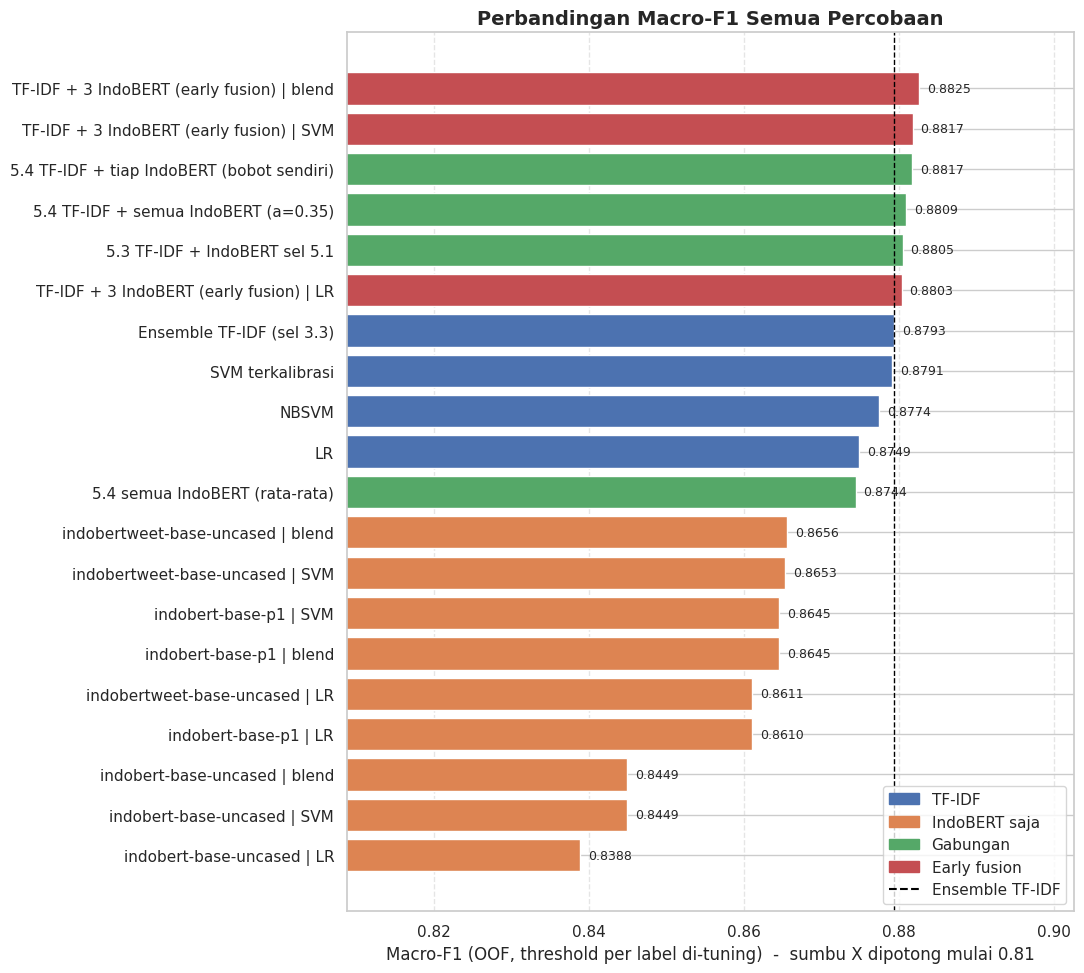

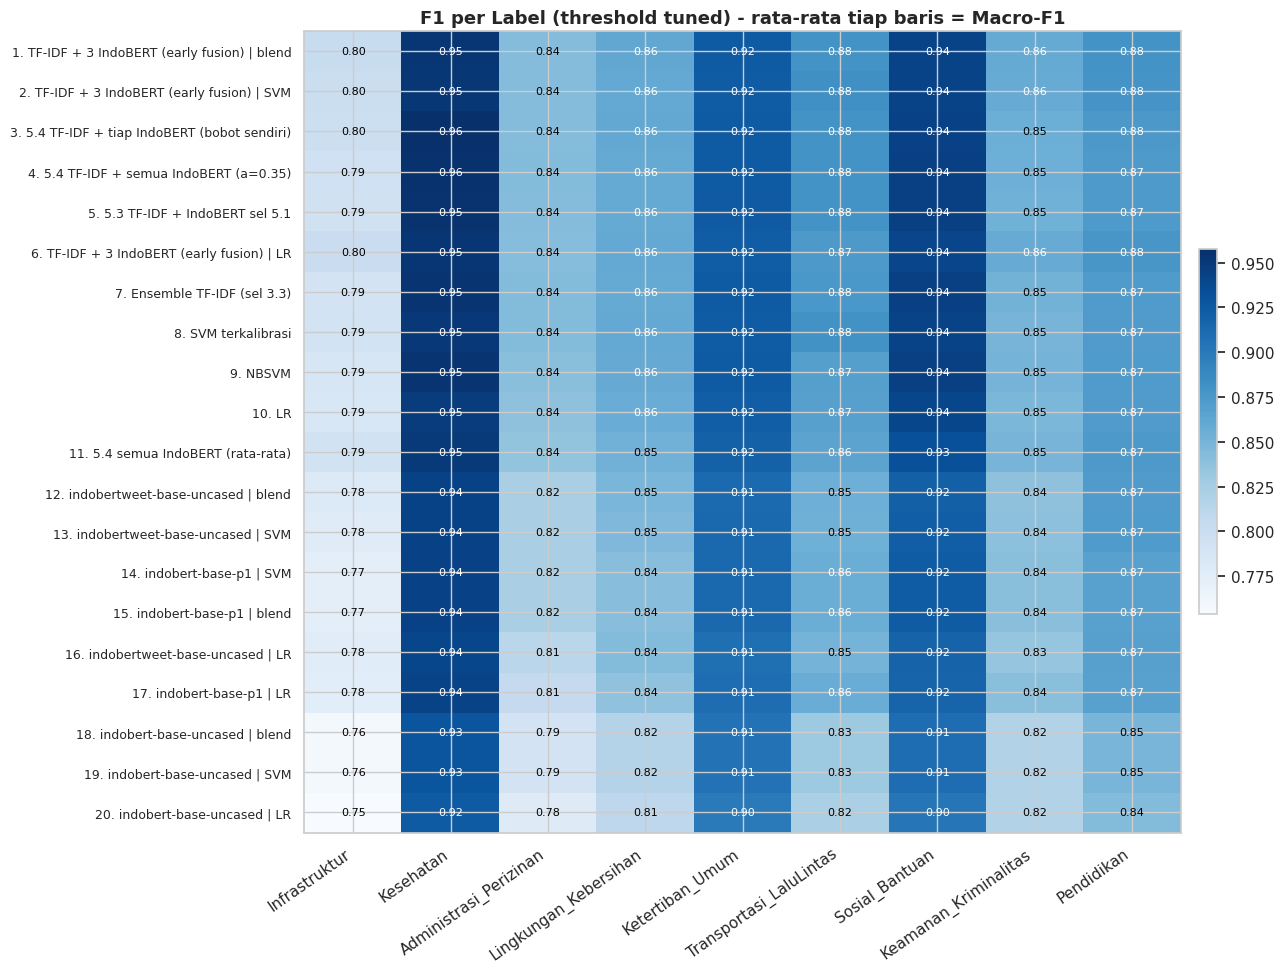


Label paling sulit (F1 terendah pada percobaan terbaik):
  Infrastruktur              F1=0.8024
  Administrasi_Perizinan     F1=0.8423
  Keamanan_Kriminalitas      F1=0.8589


In [25]:
# %% ===== SEL BARU 5.5: taruh SETELAH sel 5.4 (paling akhir) =====
# 5.5 PERBANDINGAN MACRO-F1 SEMUA PERCOBAAN (OOF, threshold per label di-tuning)
#
# Sel ini membaca hasil percobaan yang SUDAH ada di sesi (variabel dari sel 3.1-5.4) dan menghitung ulang Macro-F1
# dengan cara yang sama untuk semuanya, jadi angkanya sebanding. Percobaan yang belum dijalankan dilewati otomatis.
# Studi ablasi cleaning (sel 2.6) sengaja tidak dimasukkan: modelnya lebih sederhana (LR saja, C=4), jadi tidak sebanding.
def _g(name):
    return globals().get(name)
 
entries = []                                   # (kelompok, nama, matriks probabilitas OOF)
def _add(group, name, P):
    if P is not None:
        entries.append((group, name, np.asarray(P)))
 
# --- TF-IDF (sel 3.1 - 3.3) ---
_add('TF-IDF', 'LR',                         _g('oof_lr'))
_add('TF-IDF', 'NBSVM',                      _g('oof_nb'))
_add('TF-IDF', 'SVM terkalibrasi',           _g('oof_svm'))
_add('TF-IDF', 'Ensemble TF-IDF (sel 3.3)',  _g('oof_ensemble'))
 
# --- IndoBERT saja (sel 5.2b - 5.2d), tiap model: LR, SVM, blend ---
for n, r in (_g('BERT_RUNS') or {}).items():
    s = n.split('/')[-1]
    _add('IndoBERT saja', f'{s} | LR',    r['oof_lr'])
    _add('IndoBERT saja', f'{s} | SVM',   r['oof_svm'])
    _add('IndoBERT saja', f'{s} | blend', r['oof'])
 
# --- Gabungan = late fusion (sel 5.3 dan 5.4) ---
_add('Gabungan', '5.3 TF-IDF + IndoBERT sel 5.1', _g('oof_hybrid'))
if _g('P_avg_oof') is not None:
    _add('Gabungan', '5.4 semua IndoBERT (rata-rata)', _g('P_avg_oof'))
if all(_g(v) is not None for v in ('comps_oof', 'W4', 'W5', 'a_avg')):
    _add('Gabungan', f'5.4 TF-IDF + semua IndoBERT (a={a_avg:.2f})',  sum(w * P for w, P in zip(W4, comps_oof)))
    _add('Gabungan', '5.4 TF-IDF + tiap IndoBERT (bobot sendiri)',    sum(w * P for w, P in zip(W5, comps_oof)))
 
# --- Early fusion (sel 5.4b) ---
for n, r in (_g('FUSION_RUNS') or {}).items():
    _add('Early fusion', f'{n} | LR',    r['oof_lr'])
    _add('Early fusion', f'{n} | SVM',   r['oof_svm'])
    _add('Early fusion', f'{n} | blend', r['oof'])
 
assert entries, "Belum ada hasil percobaan di sesi ini: jalankan sel 3.1 - 3.3 terlebih dahulu"
 
rows, f1_mat = [], []
for grp, name, P in entries:
    ths, f1s, mi, ma = tune_thresholds(y_train, P)
    ma05 = f1_score(y_train, (P >= 0.5).astype(int), average='macro', zero_division=0)
    rows.append({'Kelompok': grp, 'Percobaan': name, 'Macro-F1 (tuned)': ma, 'Macro-F1 (th=0.5)': ma05, 'Micro-F1 (tuned)': mi})
    f1_mat.append(f1s)
 
cmp_df = pd.DataFrame(rows)
f1_mat = np.array(f1_mat)
base_ma = cmp_df.loc[cmp_df['Percobaan'].str.startswith('Ensemble TF-IDF'), 'Macro-F1 (tuned)']
base_ma = float(base_ma.iloc[0]) if len(base_ma) else float(cmp_df['Macro-F1 (tuned)'].iloc[0])
cmp_df['Selisih vs Ensemble TF-IDF'] = cmp_df['Macro-F1 (tuned)'] - base_ma
 
order = cmp_df['Macro-F1 (tuned)'].sort_values(ascending=False).index
cmp_sorted = cmp_df.loc[order].reset_index(drop=True)
f1_sorted = f1_mat[order]
cmp_sorted.insert(0, 'Rank', np.arange(1, len(cmp_sorted) + 1))
 
pd.set_option('display.width', 220)
print(f"Perbandingan Macro-F1 ({len(cmp_sorted)} percobaan, OOF {N_FOLDS}-fold, urut dari terbaik):\n")
print(cmp_sorted.round(4).to_string(index=False))
print(f"\nTerbaik : {cmp_sorted.iloc[0]['Percobaan']}  (Macro-F1 = {cmp_sorted.iloc[0]['Macro-F1 (tuned)']:.4f})")
print(f"Acuan   : Ensemble TF-IDF = {base_ma:.4f}")
print("Catatan : selisih < ~0.002 sebaiknya dianggap setara. Threshold & bobot dipilih dari OOF yang sama,")
print("          jadi semua skor sedikit optimistis, dan percobaan yang lebih fleksibel (lebih banyak bobot) lebih optimistis.")
 
# ---------- Diagram batang ----------
colors = {'TF-IDF': '#4c72b0', 'IndoBERT saja': '#dd8452', 'Gabungan': '#55a868', 'Early fusion': '#c44e52'}
d = cmp_sorted.iloc[::-1]                                   # terbaik di atas
fig, ax = plt.subplots(figsize=(11, max(4.5, 0.42 * len(d) + 1.5)))
bars = ax.barh(d['Percobaan'], d['Macro-F1 (tuned)'], color=[colors[g] for g in d['Kelompok']])
ax.axvline(base_ma, color='black', linestyle='--', linewidth=1, label=f'Ensemble TF-IDF = {base_ma:.4f}')
for b, v in zip(bars, d['Macro-F1 (tuned)']):
    ax.text(v + 0.001, b.get_y() + b.get_height() / 2, f'{v:.4f}', va='center', fontsize=9)
lo = max(0.0, d['Macro-F1 (tuned)'].min() - 0.03)
ax.set_xlim(lo, d['Macro-F1 (tuned)'].max() + 0.02)
ax.set_xlabel(f'Macro-F1 (OOF, threshold per label di-tuning)  -  sumbu X dipotong mulai {lo:.2f}')
ax.set_title('Perbandingan Macro-F1 Semua Percobaan', fontsize=14, fontweight='bold')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles + [plt.Line2D([0], [0], color='black', linestyle='--')],
          list(colors) + ['Ensemble TF-IDF'], loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()
 
# ---------- Heatmap F1 per label (Macro-F1 = rata-rata tiap baris) ----------
fig, ax = plt.subplots(figsize=(13, max(4.5, 0.42 * len(cmp_sorted) + 1.5)))
im = ax.imshow(f1_sorted, cmap='Blues', aspect='auto', vmin=f1_sorted.min(), vmax=f1_sorted.max())
ax.set_xticks(range(len(target_cols))); ax.set_xticklabels(target_cols, rotation=35, ha='right')
ax.set_yticks(range(len(cmp_sorted)))
ax.set_yticklabels([f"{r}. {p}" for r, p in zip(cmp_sorted['Rank'], cmp_sorted['Percobaan'])], fontsize=9)
mid = (f1_sorted.min() + f1_sorted.max()) / 2
for i in range(f1_sorted.shape[0]):
    for j in range(f1_sorted.shape[1]):
        ax.text(j, i, f'{f1_sorted[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if f1_sorted[i, j] > mid else 'black')
ax.set_title('F1 per Label (threshold tuned) - rata-rata tiap baris = Macro-F1', fontsize=13, fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02)
plt.tight_layout(); plt.show()
 
# ---------- Label tersulit & label yang paling diuntungkan ----------
best_row = f1_sorted[0]
print("\nLabel paling sulit (F1 terendah pada percobaan terbaik):")
for j in np.argsort(best_row)[:3]:
    print(f"  {target_cols[j]:<26s} F1={best_row[j]:.4f}")